In [2]:
import sys
import os

from pathlib import Path
import subprocess

import pandas as pd
import numpy as np
import scipy.stats as stats

import re

from upsetplot import *
from matplotlib import pyplot
import matplotlib.pyplot as plt
from matplotlib_venn import venn2  
import seaborn as sns
from matplotlib.colors import ListedColormap
from matplotlib.colors import to_rgb
from matplotlib.patches import Patch

import logomaker as lm
from IPython.display import Image

from Bio.SeqUtils.IsoelectricPoint import IsoelectricPoint as IP
import ast

In [3]:
from src import ms_run_class_slim

In [4]:
metadata = pd.read_csv("metadata.csv")

In [5]:
#Processing Fragpipe output

In [6]:
runs = []
for _, row in metadata.iterrows():
    runs.append(ms_run_class_slim.MSrun(row))

/mnt/raid0/ewing_sarcoma/output/Immumopeptidomics/12122025/A673/psm.tsv
/mnt/raid0/ewing_sarcoma/output/Immumopeptidomics/12122025/EW16/psm.tsv
/mnt/raid0/ewing_sarcoma/output/Immumopeptidomics/12122025/EW7/psm.tsv
/mnt/raid0/ewing_sarcoma/output/Immumopeptidomics/12122025/STA_ET_1/psm.tsv
/mnt/raid0/ewing_sarcoma/output/Immumopeptidomics/12122025/TC71/psm.tsv
/mnt/raid0/ewing_sarcoma/output/Immumopeptidomics/12122025/IC_pPDX_8/psm.tsv
/mnt/raid0/ewing_sarcoma/output/Immumopeptidomics/12122025/IC_pPDX_5/psm.tsv
/mnt/raid0/ewing_sarcoma/output/Immumopeptidomics/12122025/IC_pPDX_164/psm.tsv
/mnt/raid0/ewing_sarcoma/output/Immumopeptidomics/12122025/IC_pPDX_179/psm.tsv
/mnt/raid0/ewing_sarcoma/output/Immumopeptidomics/12122025/IC_pPDX_141/psm.tsv


In [7]:
for run in runs:
    run.isCanonical()

/mnt/raid0/ewing_sarcoma/main/src/ms_run_class_slim.py:207: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
/mnt/raid0/ewing_sarcoma/main/src/ms_run_class_slim.py:207: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
/mnt/raid0/ewing_sarcoma/main/src/ms_run_class_slim.py:207: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/i

In [8]:
psm_count = []
unique_count = []

for i in range(len(runs)):
    psm_count.append(len(runs[i].psm))
    unique_count.append(len(runs[i].unique))

In [9]:
metadata["psm_count"] = psm_count
metadata["unique_count"] = unique_count
metadata

,sample,search_engine,fdr,path,DB,hla_alleles,psm_count,unique_count
0,A673,Fragpipe,0.01,/mnt/raid0/ewing_sarcoma/output/Immumopeptidom...,uniprot_NT,HLA-A01:01|HLA-A02:01|HLA-B07:02|HLA-C07:02,20658,6255
1,EW16,Fragpipe,0.01,/mnt/raid0/ewing_sarcoma/output/Immumopeptidom...,uniprot_NT,HLA-A02:01|HLA-B44:03|HLA-B51:01|HLA-C16:01|HL...,40617,12991
2,EW7,Fragpipe,0.01,/mnt/raid0/ewing_sarcoma/output/Immumopeptidom...,uniprot_NT,HLA-A02:01|HLA-A03:01|HLA-B35:01|HLA-B51:01|HL...,14981,3223
3,STA-ET-1,Fragpipe,0.01,/mnt/raid0/ewing_sarcoma/output/Immumopeptidom...,uniprot_NT,HLA-A02:01|HLA-A30:04|HLA-B51:08|HLA-B44:02|HL...,24414,6967
4,TC71,Fragpipe,0.01,/mnt/raid0/ewing_sarcoma/output/Immumopeptidom...,uniprot_NT,HLA-A68:01|HLA-A02:01|HLA-B44:02|HLA-B15:01|HL...,25777,9068
5,IC-pPDX-8,Fragpipe,0.01,/mnt/raid0/ewing_sarcoma/output/Immumopeptidom...,uniprot_NT,HLA-A02:01|HLA-A33:03|HLA-B15:03|HLA-B51:08|HL...,3135,869
6,IC-pPDX-5,Fragpipe,0.01,/mnt/raid0/ewing_sarcoma/output/Immumopeptidom...,uniprot_NT,HLA-A03:01|HLA-A02:01|HLA-B50:01|HLA-B52:01|HL...,9493,4365
7,IC-pPDX-164,Fragpipe,0.01,/mnt/raid0/ewing_sarcoma/output/Immumopeptidom...,uniprot_NT,HLA-A01:01|HLA-B57:01|HLA-C03:04|HLA-C07:02,6872,1859
8,IC-pPDX-179,Fragpipe,0.01,/mnt/raid0/ewing_sarcoma/output/Immumopeptidom...,uniprot_NT,HLA-A30:01|HLA-A32:01|HLA-B40:02|HLA-B51:01|HL...,9009,3142
9,IC-pPDX-141,Fragpipe,0.01,/mnt/raid0/ewing_sarcoma/output/Immumopeptidom...,uniprot_NT,HLA-A30:01|HLA-A02:01|HLA-B35:03|HLA-B44:03|HL...,3609,1525


In [10]:
palette_class = {"Canonical": "#bcbcbc", "Ambiguous": "#b63fc0", "Non canonical": "#eaaa6a", "Contaminant": "#9e6156"}

In [11]:
def combine(counts, percentages):
    fmt = "{}\n{:.1f}%".format
    return [fmt(c, p) for c, p in zip(counts, percentages)]

In [12]:
def plot_class_distribution(run_, max_, save_dir=None):
    data_ = run_.unique.copy() 
    data_['class'] = pd.Categorical(data_["class"], categories=["Canonical", "Ambiguous", "Non canonical", "Contaminant"])

    plt.figure(figsize=(6, 3))
    ax = sns.countplot(data=data_, x='class', palette={"Canonical": "#bcbcbc", "Ambiguous": "#b63fc0", "Non canonical": "#eaaa6a", "Contaminant": "#9e6156"}, width=0.75)
    counts = data_['class'].value_counts()[["Canonical", "Ambiguous", "Non canonical", "Contaminant"]]
    percentages = (counts / counts.sum()) * 100
    annotations = combine(counts.values, percentages.values)
    #print('Class distribution:')
    #print(counts)
    for p, annotation in zip(ax.patches, annotations):
        ax.annotate(annotation, (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=9)

    ax.set_ylim(0, max_)
    ax.set_ylabel("Count")
    ax.set_title(f"{run_.sample} {run_.search_engine} peptides count FDR = {run_.fdr}")
    plt.xticks(rotation=0)

    ax.yaxis.grid(True, linestyle='--', linewidth=0.5, color='lightgray')
    
    sns.despine()

    if save_dir:
        plt.savefig(f"Class_distribution_{run_.sample}.png", dpi=600, bbox_inches='tight')
        plt.show()

/tmp/ipykernel_4106705/1387731820.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

/tmp/ipykernel_4106705/1387731820.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

/tmp/ipykernel_4106705/1387731820.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

/tmp/ipykernel_4106705/1387731820.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

/tmp/ipykernel_4106705/1387731820.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprec

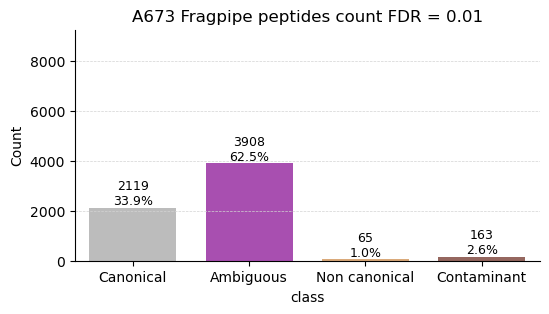

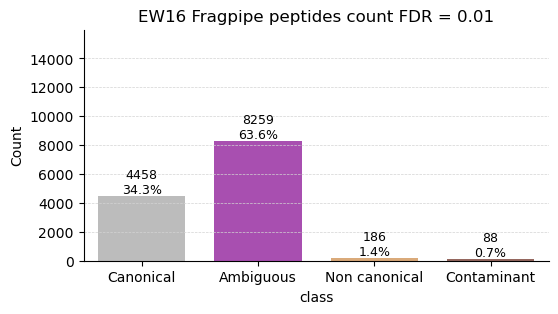

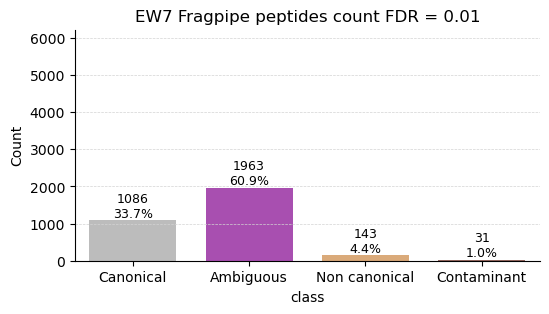

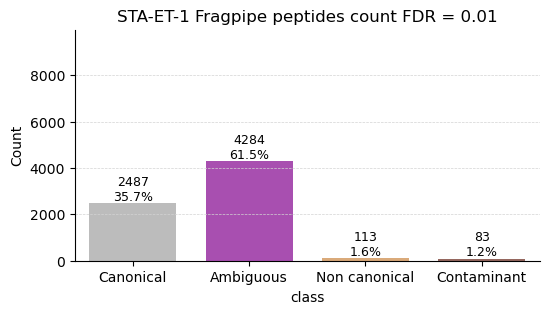

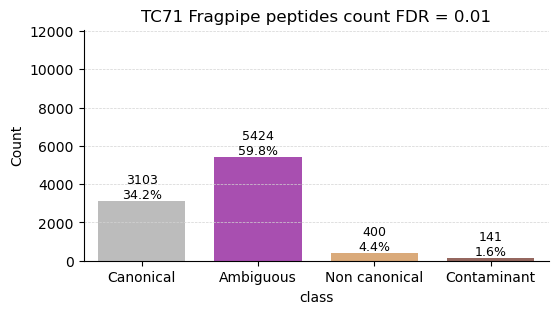

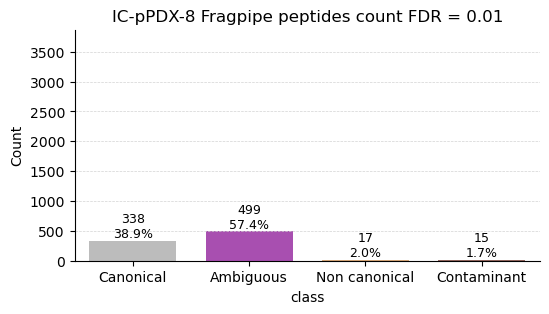

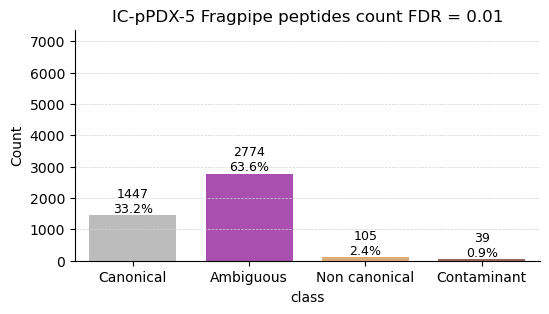

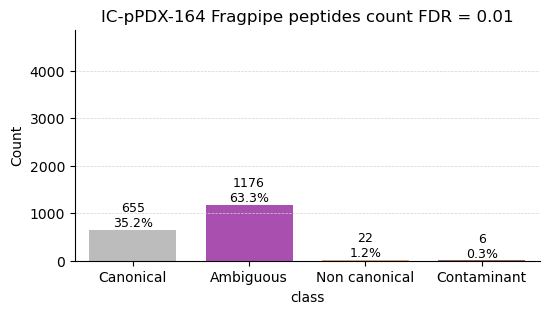

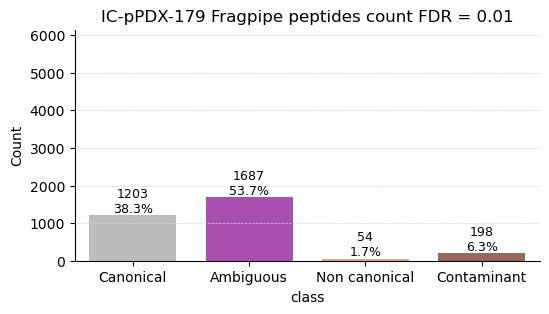

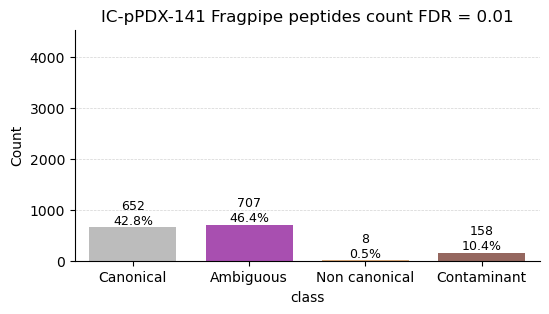

In [13]:
for run in runs:
    plot_class_distribution(run, max_ = len(run.unique)+3000)

In [14]:
def plot_length_distribution(run_, max_, save_dir=None):
    data_ = pd.DataFrame({
        "length": [len(x) for x in run_.unique["seq_clear"]],
        "seq": run_.unique["seq_clear"]
    })
    
    data_["length"] = data_["length"].astype('category')

    plt.figure(figsize=(4, 3))
    ax = sns.countplot(data=data_, x='length', color='black', width=0.6)

    counts = data_['length'].value_counts().reindex(data_['length'].cat.categories)
    percentages = (counts / counts.sum()) * 100
    annotations = combine(counts.values, percentages.values)
    
    for p, annotation in zip(ax.patches, annotations):
        ax.annotate(annotation, (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=8)

    ax.set_ylim(0, max_)
    ax.set_xlabel("Peptide length (aa)")
    ax.set_ylabel("Count")
    ax.set_title(f"Total {run_.sample} {run_.search_engine} \n peptides lengths distribution FDR = {run_.fdr}")
    
    ax.yaxis.grid(True, linestyle='--', linewidth=0.5, color='lightgray')
    
    sns.despine()

    if save_dir:
        plt.savefig(f"length_distrib_{run_.sample}_{run_.search_engine}_{run_.fdr}.png", dpi=600, bbox_inches='tight')
        plt.show()
    
    for klass in ["Canonical", "Ambiguous", "Non canonical", "Contaminant"]:
        max_for_klass = len(run_.unique[run_.unique['class']==klass])
        data_t = pd.DataFrame({
		"length": [len(x) for x in run_.unique[run_.unique['class']==klass]["seq_clear"]],
		"seq": run_.unique[run_.unique['class']==klass]["seq_clear"]
        })

        data_t["length"] = data_t["length"].astype('category')
        plt.figure(figsize=(4, 3))
        ax = sns.countplot(data=data_t, x='length', color='black', width=0.6)

        counts = data_t['length'].value_counts().reindex(data_t['length'].cat.categories)
        percentages = (counts / counts.sum()) * 100
        annotations = combine(counts.values, percentages.values)

        for p, annotation in zip(ax.patches, annotations):
                ax.annotate(annotation, (p.get_x() + p.get_width() / 2., p.get_height()),
                                        ha='center', va='bottom', fontsize=8)

        ax.set_ylim(0, max_for_klass+50)
        ax.set_xlabel("Peptide length (aa)")
        ax.set_ylabel("Count")
        ax.set_title(f"{run_.sample} {klass} \n peptides lengths distribution FDR = {run_.fdr}")

        ax.yaxis.grid(True, linestyle='--', linewidth=0.5, color='lightgray')

        sns.despine()

        if save_dir:
            plt.savefig(f"length_distrib_{klass}_{run_.sample}_{run_.search_engine}_{run_.fdr}.png", dpi=600, bbox_inches='tight')
            plt.show()

/tmp/ipykernel_4106705/3405519532.py:9: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.


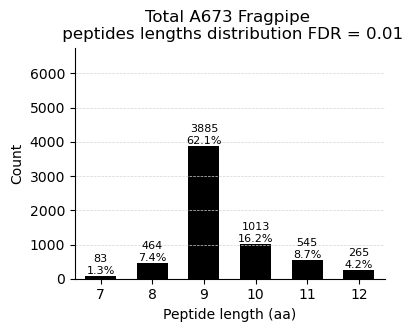

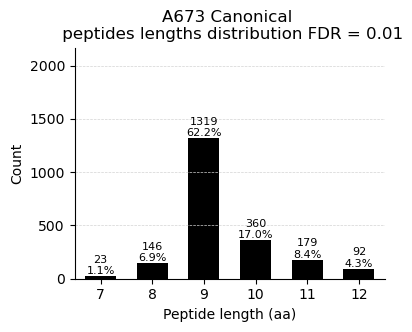

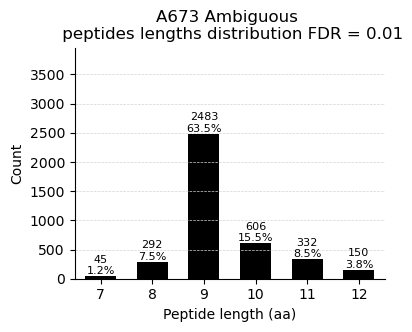

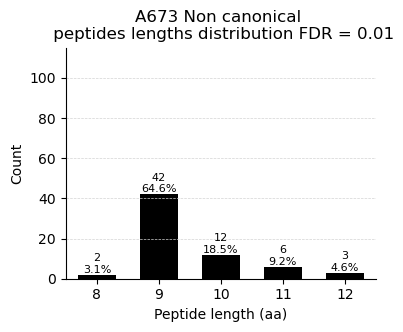

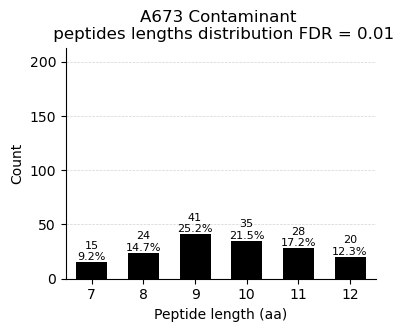

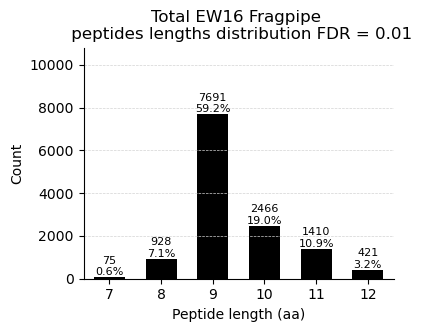

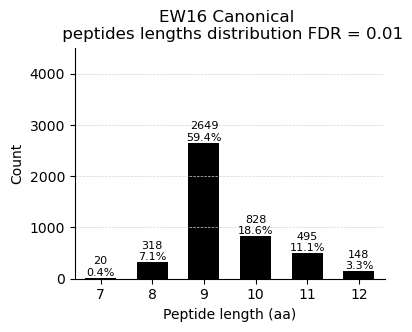

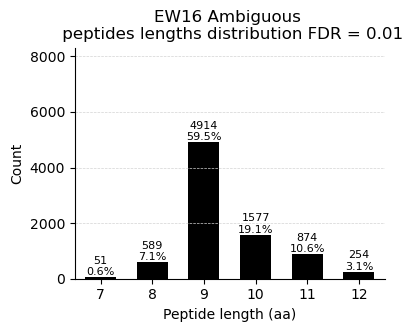

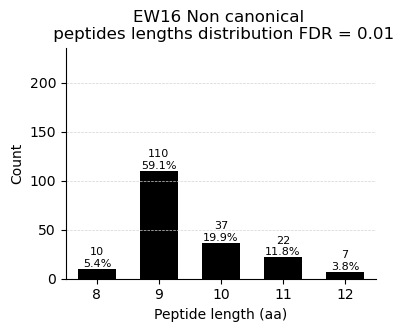

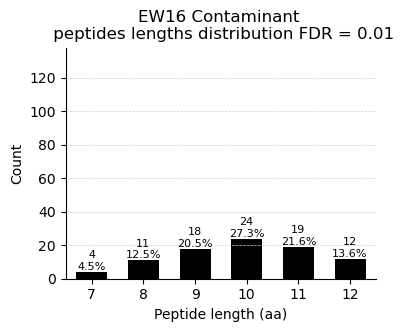

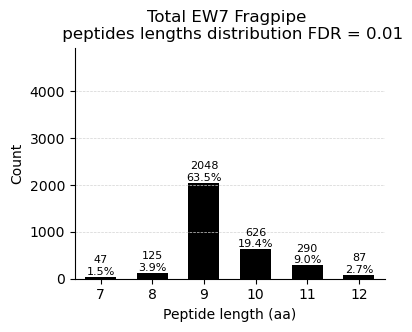

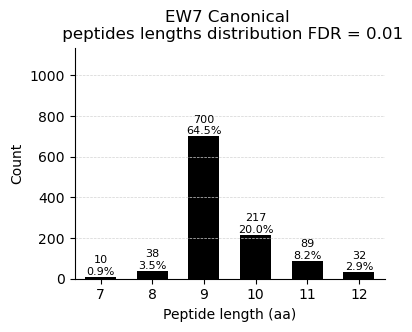

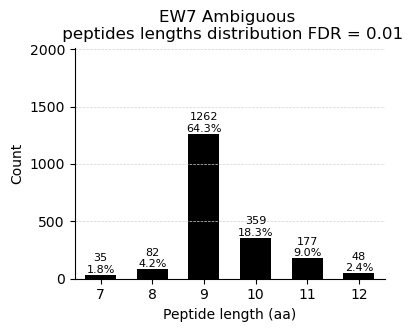

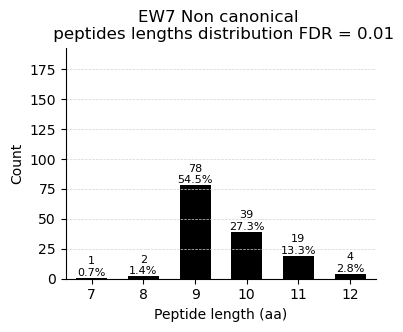

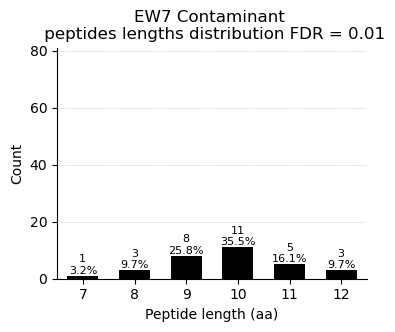

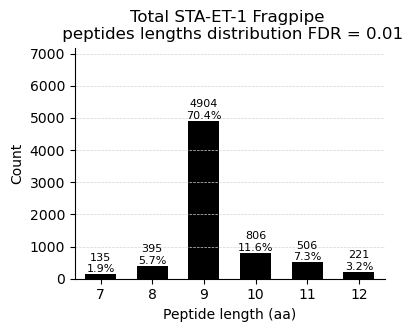

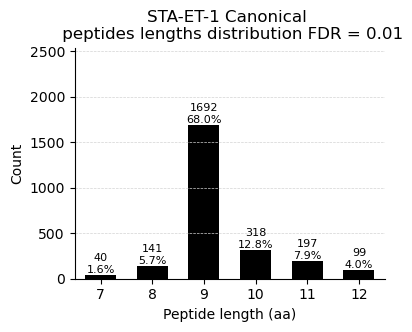

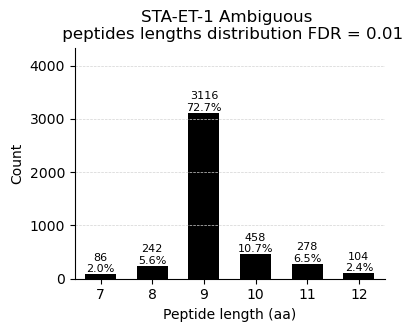

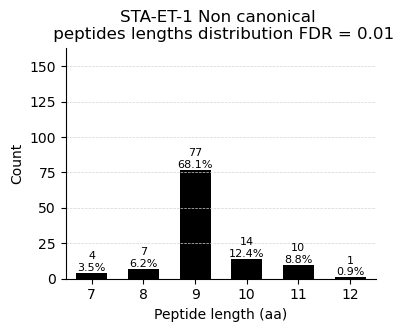

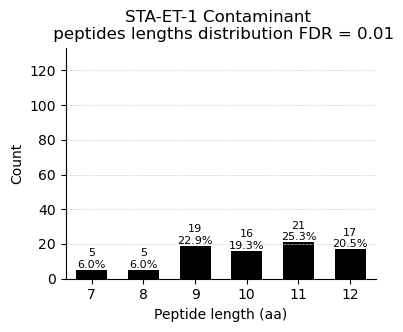

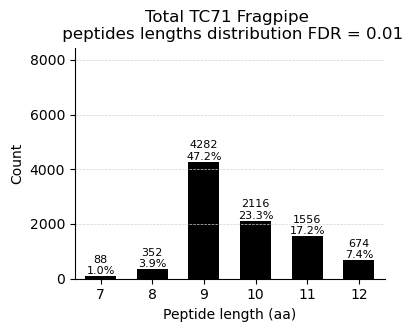

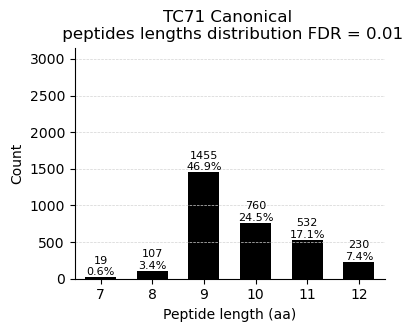

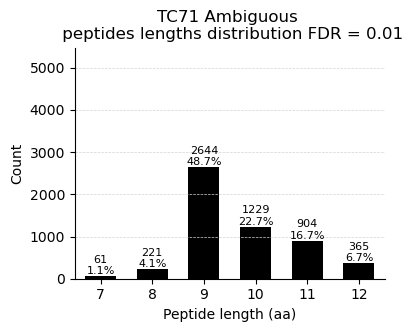

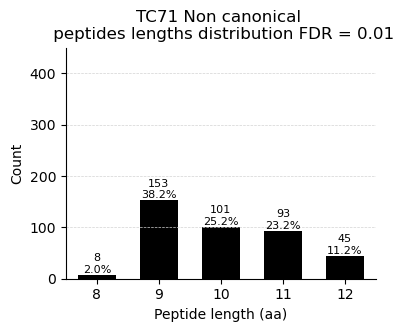

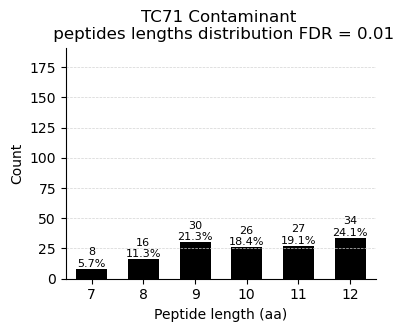

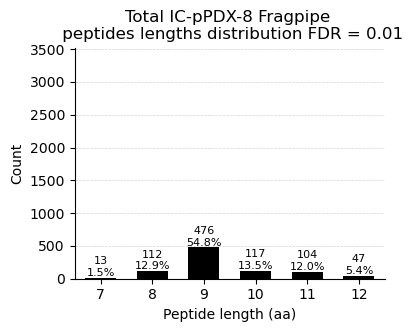

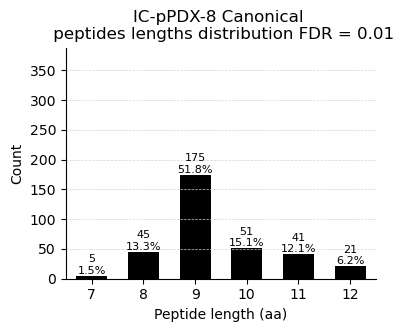

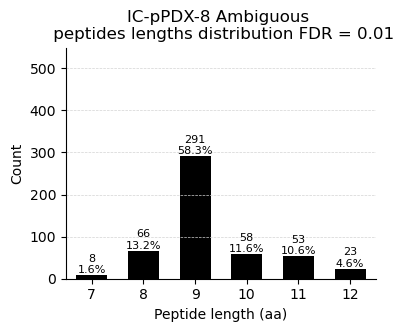

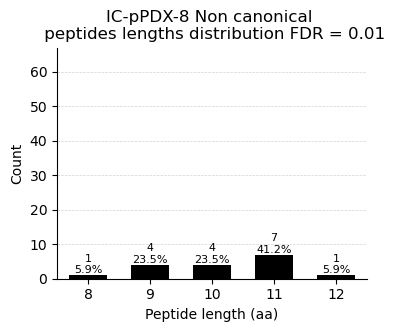

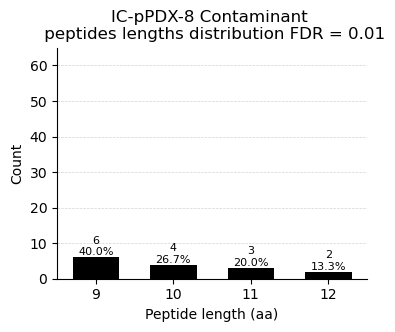

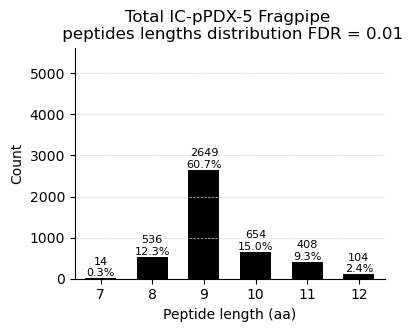

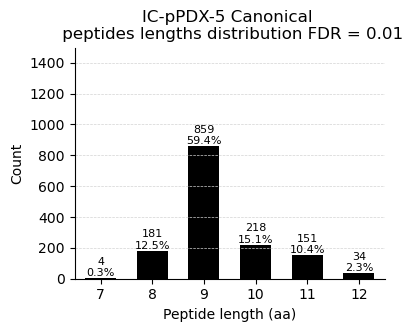

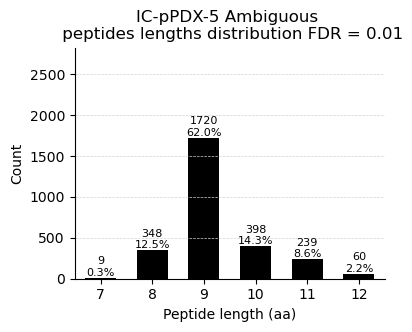

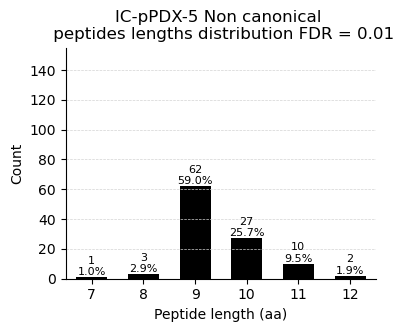

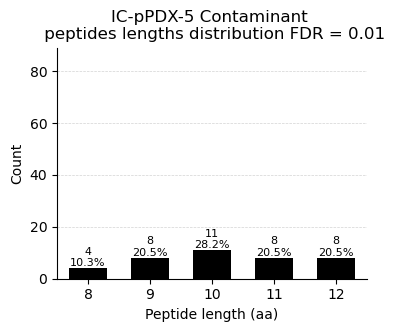

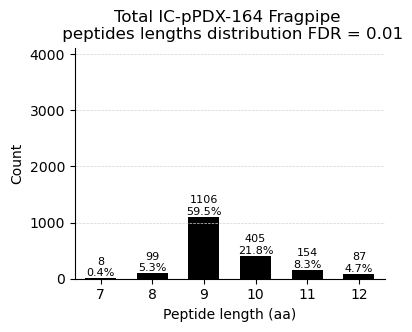

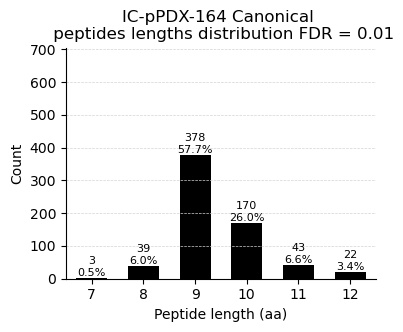

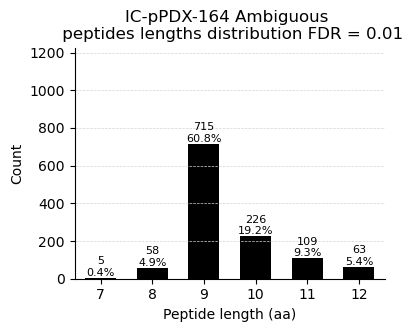

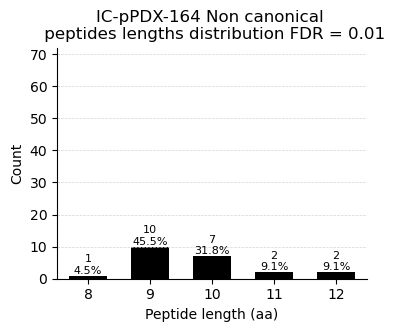

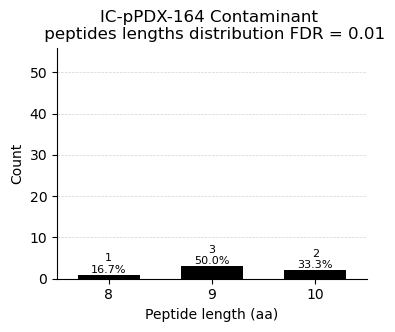

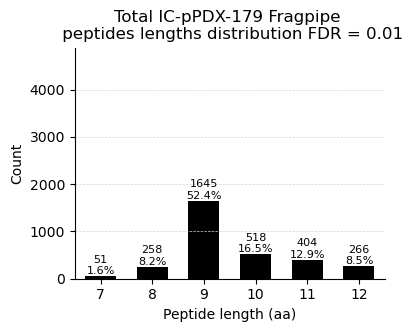

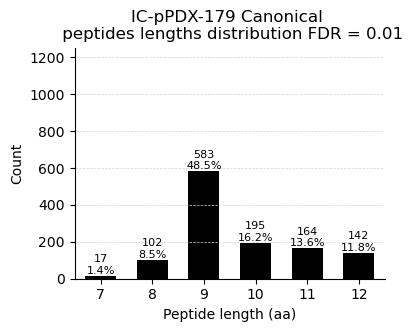

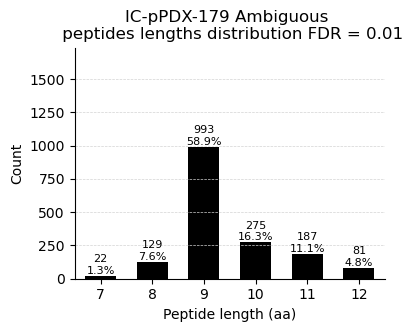

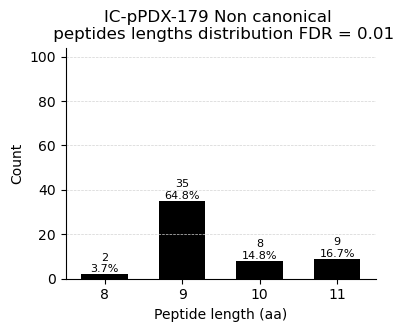

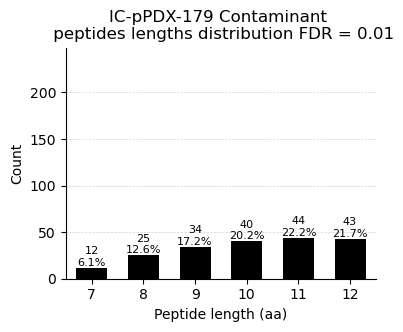

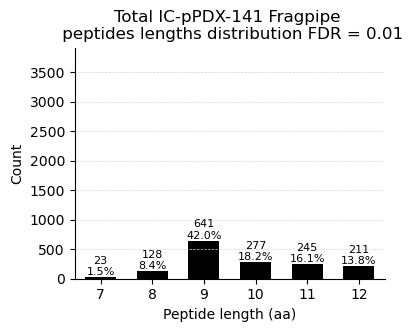

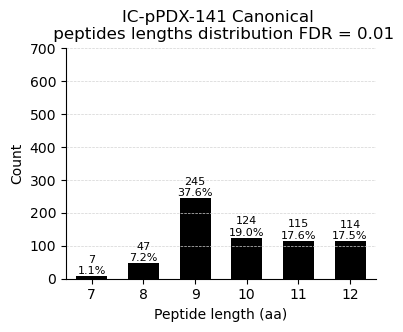

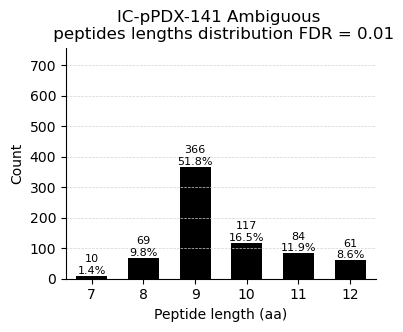

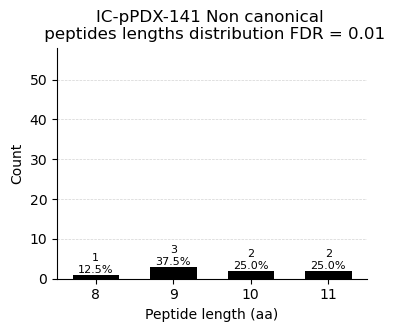

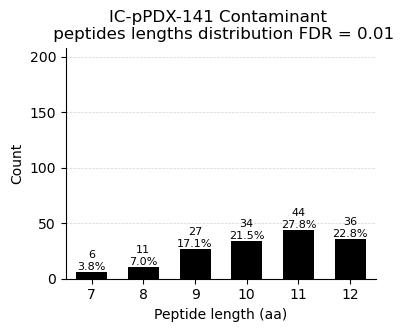

In [15]:
for run in runs:
    plot_length_distribution(run, max_ = 0.6*len(run.unique)+3000)

In [16]:
#Source: https://www.biob.in/2014/05/hydrophobicity-plot-using-biopython.html

from Bio.SeqRecord import SeqRecord
from Bio.Seq import Seq

kd = { 'A': 1.8,'R':-4.5,'N':-3.5,'D':-3.5,'C': 2.5,
       'Q':-3.5,'E':-3.5,'G':-0.4,'H':-3.2,'I': 4.5,
       'L': 3.8,'K':-3.9,'M': 1.9,'F': 2.8,'P':-1.6,
       'S':-0.8,'T':-0.7,'W':-0.9,'Y':-1.3,'V': 4.2 }

moon = {'F':1.43,'L':1.26,'I':1.15,'P':1.13,'Y':0.94,
        'V':0.80,'M':0.79,'W':0.63,'A':0.46,'C':0.24,
        'E':-0.27,'G':-0.30,'T':-0.33,'S':-0.35,'D':-0.85,
        'Q':-0.88,'N':-1.08,'R':-1.19,'H':-1.65,'K':-1.93}

In [17]:
palette_kde = {"Canonical": "#a6a6a6", "Both": "#b63fc0", "Non canonical": "#eaaa6a"}

In [18]:
def plot_corr_HI_RT(run_, scale_=kd, save_dir=None):
    HI = []
    rts = []

    data_ = run_.unique[(run_.unique['class']=="Canonical")|(run_.unique['class']=="Non canonical")]

    for index, row in data_.iterrows():
        seq = row['seq_clear']
        num_residue = len(seq)
        values = []

        for residue in seq:
            values.append(scale_[residue])

        HI.append(sum(values))
        rts.append(row['rt'] / 60)

    klass = np.array(data_["class"])
    dataset = pd.DataFrame({'RT': np.array(rts), 'HI': np.array(HI), 'Class': klass}) 

    plt.figure(figsize=(5, 3.5))

    subset_canonical = dataset[dataset['Class'] == "Canonical"]
    sns.scatterplot(data=subset_canonical, x='RT', y='HI', color="#bcbcbc", alpha=0.6, label="Canonical")

    subset_noncanonical = dataset[dataset['Class'] == "Non canonical"]
    sns.scatterplot(data=subset_noncanonical, x='RT', y='HI', color="#eaaa6a", alpha=0.6, label="Non canonical")

    ax = plt.gca()
    for label in dataset['Class'].unique():
        subset = dataset[dataset['Class'] == label]
        sns.kdeplot(x=subset['RT'], y=subset['HI'], ax=ax, fill=False, color=palette_kde[label], levels=5)

    ax.set_xlabel("Retention time (minutes)")
    ax.set_ylabel("Hydrophobicity index")
    ax.set_title(f"{run_.sample} {run_.search_engine} peptides HI vs rt FDR = {run_.fdr}")
    ax.legend()

    ax.yaxis.grid(True, linestyle='--', linewidth=0.5, color='lightgray')
    ax.set(xlim=(0, None))
    sns.despine()

    if save_dir:
        plt.savefig(f"Correlation_HI_RT_{run_.sample}_{run_.search_engine}_{run_.fdr}.png", dpi=600, bbox_inches='tight')
        plt.show()

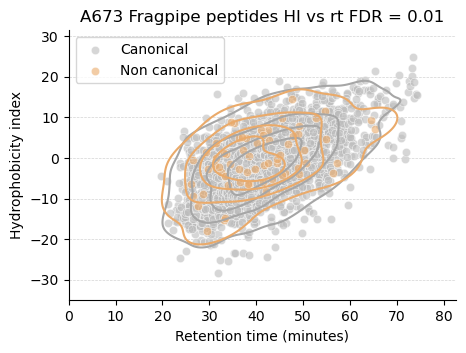

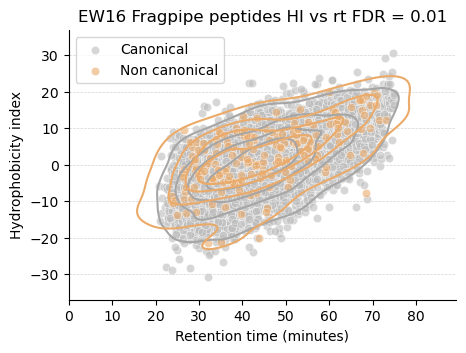

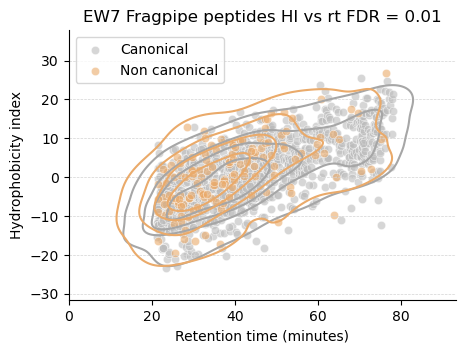

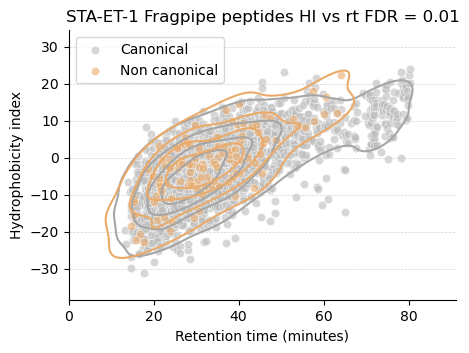

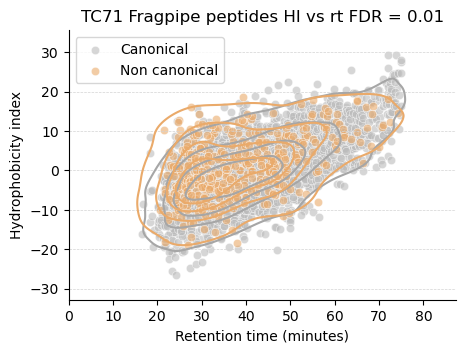

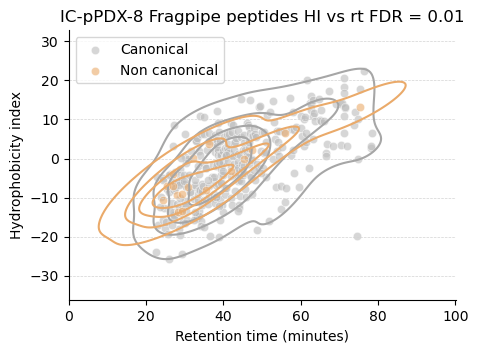

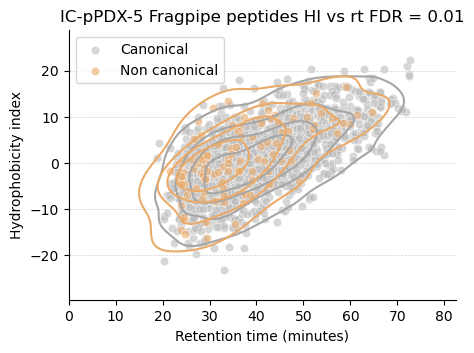

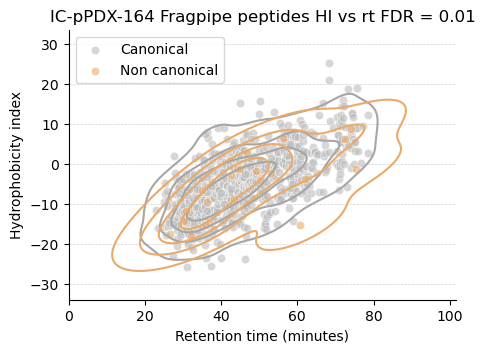

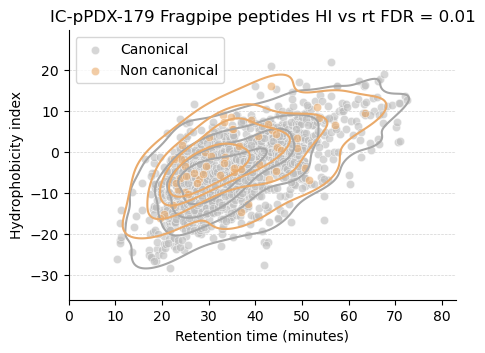

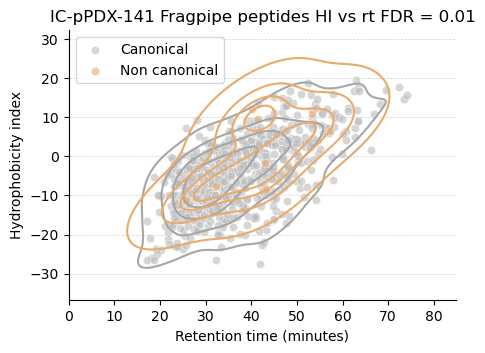

In [19]:
for run in runs:
    plot_corr_HI_RT(run)

In [20]:
!mkdir HLA_binding
outDir = "HLA_binding"
os.chdir(outDir)

mkdir: cannot create directory ‘HLA_binding’: File exists


In [21]:
for run_ in runs:
    with open(f"{run_.sample}_{run_.search_engine}_{run_.fdr}.pep", 'w') as file:
        for pep in run_.unique['seq_clear'].tolist():
            if 7<len(pep)<15:
                file.write(pep+'\n')

In [22]:
def hla_from_short_to_long(string):
    string = string[:3]+':'+string[3:]
    string = 'HLA-'+string
    return string 

def hla_from_long_to_short(string):
    string = string.replace('HLA-', '')
    string = string.replace(':', '')
    return string 

In [23]:
for run_ in runs:
    print("/home/mariia/Desktop/netMHCpan-4.1/netMHCpan", 
                    f"-a {','.join(run_.hla)}",  # HLA alleles
                    f"-p {run_.sample}_{run_.search_engine}_{run_.fdr}.pep",            # peptide list
                    f"-xls -xlsfile {run_.sample}_{run_.search_engine}_{run_.fdr}_NetMHCpan_out.xls")

    #run_netMHCpan(run_)
    #print("/home/mariia/Desktop/MixMHCpred/MixMHCpred", 
                    #f"-i {run_.sample}_{run_.search_engine}_{run_.fdr}.pep",
                    #f"-o {run_.sample}_{run_.search_engine}_{run_.fdr}_MixMHCpred_out", f"--alleles {','.join(run_.hla)}")
    #run_MixMHCpred(run_)

/home/mariia/Desktop/netMHCpan-4.1/netMHCpan -a HLA-A01:01,HLA-A02:01,HLA-B07:02,HLA-C07:02 -p A673_Fragpipe_0.01.pep -xls -xlsfile A673_Fragpipe_0.01_NetMHCpan_out.xls
/home/mariia/Desktop/netMHCpan-4.1/netMHCpan -a HLA-A02:01,HLA-B44:03,HLA-B51:01,HLA-C16:01,HLA-C05:01 -p EW16_Fragpipe_0.01.pep -xls -xlsfile EW16_Fragpipe_0.01_NetMHCpan_out.xls
/home/mariia/Desktop/netMHCpan-4.1/netMHCpan -a HLA-A02:01,HLA-A03:01,HLA-B35:01,HLA-B51:01,HLA-C04:01,HLA-C15:02 -p EW7_Fragpipe_0.01.pep -xls -xlsfile EW7_Fragpipe_0.01_NetMHCpan_out.xls
/home/mariia/Desktop/netMHCpan-4.1/netMHCpan -a HLA-A02:01,HLA-A30:04,HLA-B51:08,HLA-B44:02,HLA-C05:01,HLA-C16:02 -p STA-ET-1_Fragpipe_0.01.pep -xls -xlsfile STA-ET-1_Fragpipe_0.01_NetMHCpan_out.xls
/home/mariia/Desktop/netMHCpan-4.1/netMHCpan -a HLA-A68:01,HLA-A02:01,HLA-B44:02,HLA-B15:01,HLA-C03:03,HLA-C05:01 -p TC71_Fragpipe_0.01.pep -xls -xlsfile TC71_Fragpipe_0.01_NetMHCpan_out.xls
/home/mariia/Desktop/netMHCpan-4.1/netMHCpan -a HLA-A02:01,HLA-A33:03,HL

In [24]:
def plot_NetMHCpan_binding_results(run_, directory, output_=None):
    df = pd.read_csv(directory+f'/{run_.sample}_{run_.search_engine}_{run_.fdr}_NetMHCpan_out.xls', index_col=1, sep="\t", header=1) 
    with open(directory+f'/{run_.sample}_{run_.search_engine}_{run_.fdr}_NetMHCpan_out.xls') as my_file:
        hlas = my_file.readline().rstrip('\n').strip('\t').split('\t\t\t\t')
    df = df.rename(columns={'EL_Rank': 'EL_Rank.0'})
    df =df.reset_index()

    #plot all per allele
    counts_strong = []
    counts_weak = []
    for i, hla in enumerate(hlas):
        df[f'Strong_binder_{hla}'] = df[f'EL_Rank.{i}']<0.5
        df[f'Weak_binder_{hla}'] = (df[f'EL_Rank.{i}']<2)&(df[f'EL_Rank.{i}']>=0.5)
        counts_strong.append(df[f'Strong_binder_{hla}'].sum())
        counts_weak.append(df[f'Weak_binder_{hla}'].sum())
    allele_binder_counts = pd.DataFrame.from_dict({'Allele': hlas, 'Count_strong': counts_strong, 'Count_weak': counts_weak})
    #print(allele_binder_counts)
    bar = allele_binder_counts.plot(kind = 'bar',x='Allele', stacked = True, color = ["#00008b", "#4169e1"], zorder=2)
    bar.yaxis.grid(True, linestyle='--', linewidth=0.5, color='lightgray', zorder=0)
    for i, row in allele_binder_counts.iterrows():
        plt.text(i, row['Count_strong'], str(row['Count_strong']), ha="center", va="bottom", zorder=3)
        plt.text(i, row['Count_strong']+row['Count_weak'], str(row['Count_weak']), ha="center", va="bottom", zorder=3)
    bar.set_ylabel("Count of binders per allele")
    bar.set_title(f"All {run_.sample} {run_.search_engine} {run_.fdr} \n NetMHCpan", fontsize=16, weight='bold')
    plt.xticks(rotation=45)
    sns.despine()
    plt.tight_layout()
    plt.savefig(f"{run_.sample}_{run_.search_engine}_{run_.fdr}_NetMHCpan_binding_all_perall.png", dpi=600, bbox_inches='tight')
    plt.show()

    #plot all total
    df['Binder'] = df['NB'] != 0
    plt.figure(figsize=(2, 3))
    bar_plot = sns.barplot(df, y='Binder', errorbar=None, color="#00008b", zorder=3)
    bar_plot.text(0,  df['Binder'].mean(), df['Binder'].sum(), ha="center", va="bottom", zorder=2)
    bar_plot.yaxis.grid(True, linestyle='--', linewidth=0.5, color='lightgray')
    bar_plot.set(ylim=(None, 1.0))
    bar_plot.set_ylabel("Fraction of binders")
    bar_plot.set_title(f"All {run_.sample} {run_.search_engine} {run_.fdr} \n NetMHCpan", fontsize=16, weight='bold')
    sns.despine()
    plt.tight_layout()
    plt.savefig(f"{run_.sample}_{run_.search_engine}_{run_.fdr}_NetMHCpan_binding_all.png", dpi=600, bbox_inches='tight')
    plt.show()

    non_can = run_.unique[run_.unique['class']=='Non canonical']['seq_clear'].tolist()
    mask = df['Peptide'].isin(non_can)
    df_non_can = df[mask]

    #plot non canonical per allele
    counts_strong = []
    counts_weak = []
    for i, hla in enumerate(hlas):
        df_non_can[f'Strong_binder_{hla}'] = df_non_can[f'EL_Rank.{i}']<0.5
        df_non_can[f'Weak_binder_{hla}'] = (df_non_can[f'EL_Rank.{i}']<2)&(df_non_can[f'EL_Rank.{i}']>=0.5)
        counts_strong.append(df_non_can[f'Strong_binder_{hla}'].sum())
        counts_weak.append(df_non_can [f'Weak_binder_{hla}'].sum())
    allele_binder_counts = pd.DataFrame.from_dict({'Allele': hlas, 'Count_strong': counts_strong, 'Count_weak': counts_weak})
    #print(allele_binder_counts)
    bar = allele_binder_counts.plot(kind = 'bar',x='Allele', stacked = True, color = ["#00008b", "#4169e1"], zorder=2)
    bar.yaxis.grid(True, linestyle='--', linewidth=0.5, color='lightgray', zorder=0)
    for i, row in allele_binder_counts.iterrows():
        if row['Count_strong'] != 0:
            plt.text(i, row['Count_strong'], str(row['Count_strong']), ha="center", va="bottom", zorder=3)
        if row['Count_weak'] != 0:
            plt.text(i, row['Count_strong']+row['Count_weak'], str(row['Count_weak']), ha="center", va="bottom", zorder=3)
    bar.set_ylabel("Count of binders per allele")
    bar.set_title(f"Neotranscripts {run_.sample} {run_.search_engine} {run_.fdr} \n NetMHCpan", fontsize=16, weight='bold')
    plt.xticks(rotation=45)
    sns.despine()
    plt.tight_layout()
    plt.savefig(f"{run_.sample}_{run_.search_engine}_{run_.fdr}_NetMHCpan_binding_NC_perall.png", dpi=600, bbox_inches='tight')
    plt.show()

    #plot non canonical total
    df_non_can['Binder'] = df_non_can['NB'] != 0
    plt.figure(figsize=(2, 3))
    bar_plot = sns.barplot(df_non_can , y='Binder', errorbar=None, color="#00008b", zorder=3)
    bar_plot.text(0,  df_non_can['Binder'].mean(), df_non_can['Binder'].sum(), ha="center", va="bottom", zorder=2)
    bar_plot.yaxis.grid(True, linestyle='--', linewidth=0.5, color='lightgray')
    bar_plot.set(ylim=(None, 1.0))
    bar_plot.set_ylabel("Fraction of binders")
    bar_plot.set_title(f"Neotranscripts \n {run_.sample} {run_.search_engine} {run_.fdr} \n NetMHCpan", fontsize=16, weight='bold')
    sns.despine()
    plt.tight_layout()
    plt.savefig(f"{run_.sample}_{run_.search_engine}_{run_.fdr}_NetMHCpan_binding_NC.png", dpi=600, bbox_inches='tight')
    plt.show()

In [27]:
os.chdir("..")
!pwd

/mnt/raid0/ewing_sarcoma/main


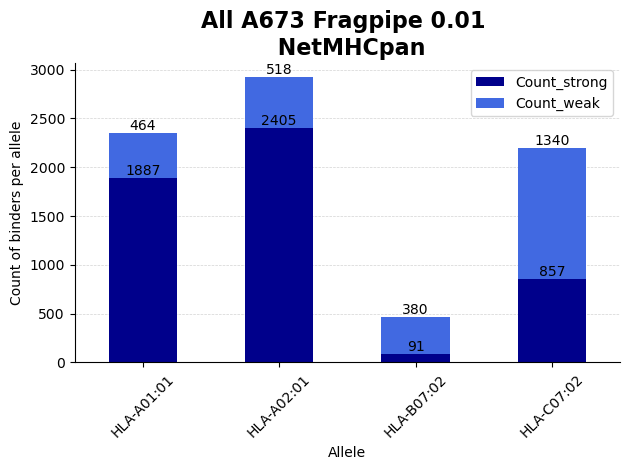

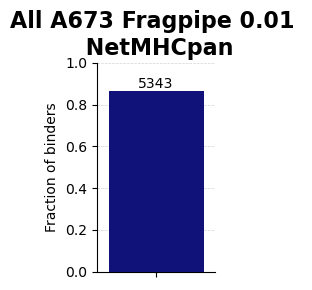

/tmp/ipykernel_4106705/740976126.py:53: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
/tmp/ipykernel_4106705/740976126.py:54: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


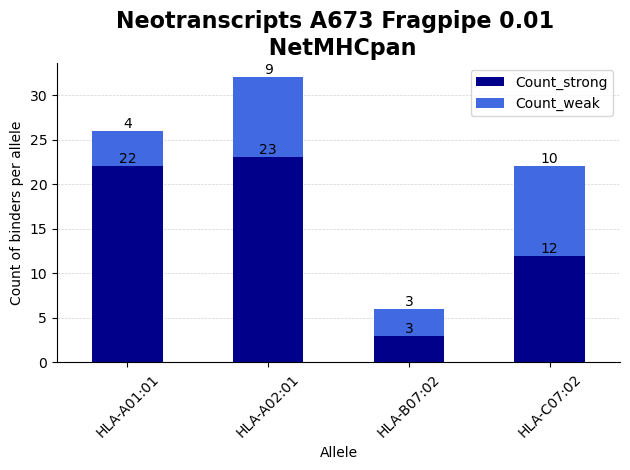

/tmp/ipykernel_4106705/740976126.py:75: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


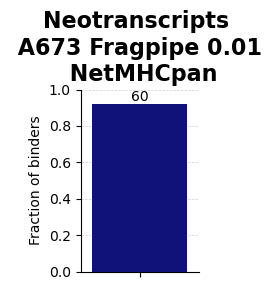

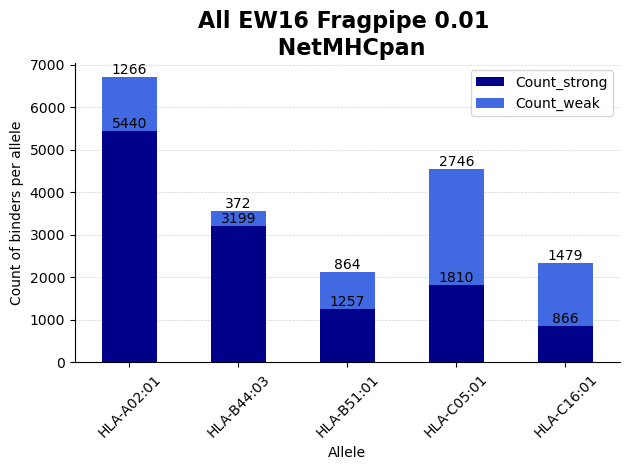

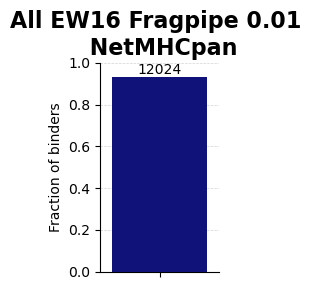

/tmp/ipykernel_4106705/740976126.py:53: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
/tmp/ipykernel_4106705/740976126.py:54: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


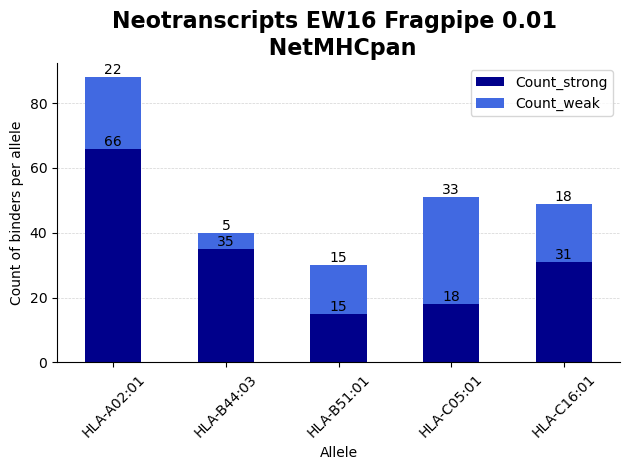

/tmp/ipykernel_4106705/740976126.py:75: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


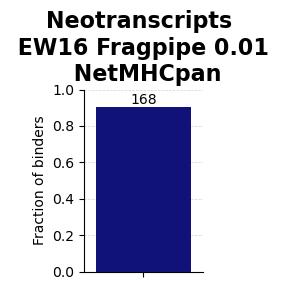

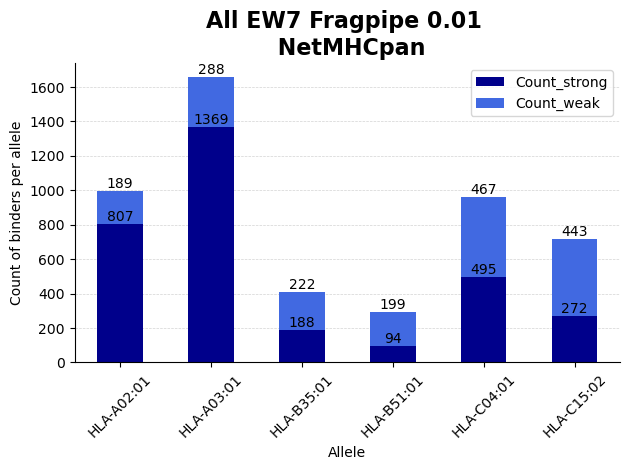

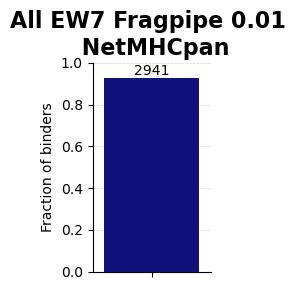

/tmp/ipykernel_4106705/740976126.py:53: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
/tmp/ipykernel_4106705/740976126.py:54: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


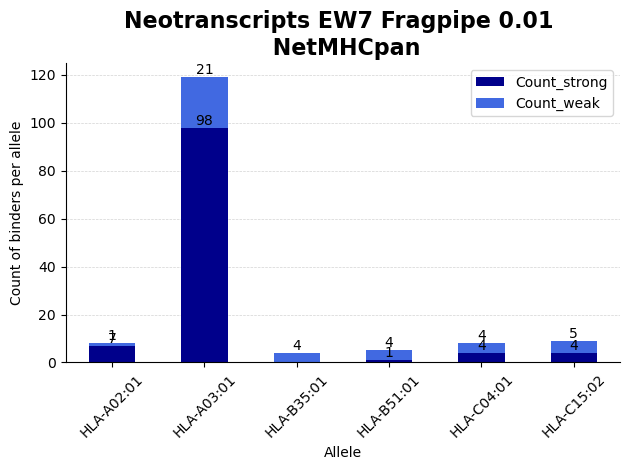

/tmp/ipykernel_4106705/740976126.py:75: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


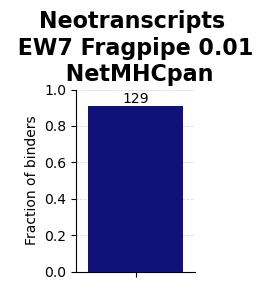

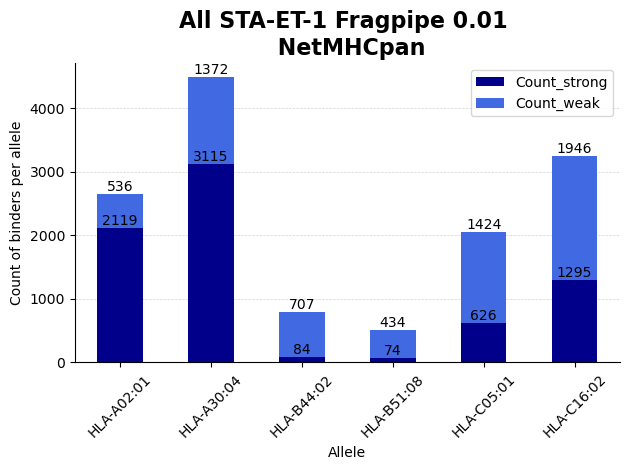

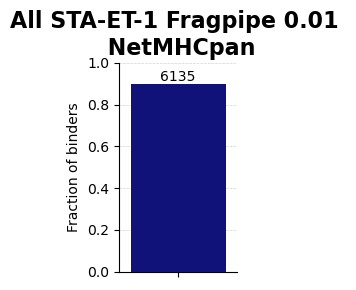

/tmp/ipykernel_4106705/740976126.py:53: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
/tmp/ipykernel_4106705/740976126.py:54: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


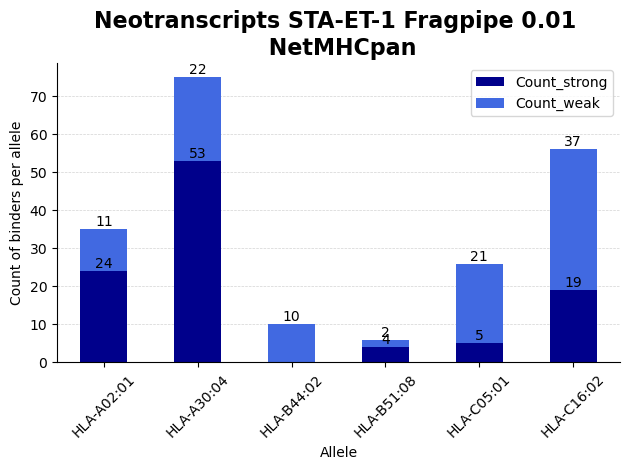

/tmp/ipykernel_4106705/740976126.py:75: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


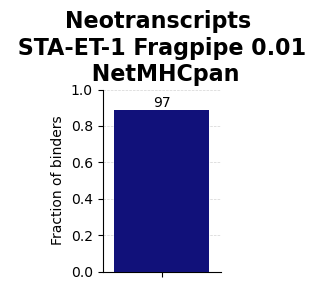

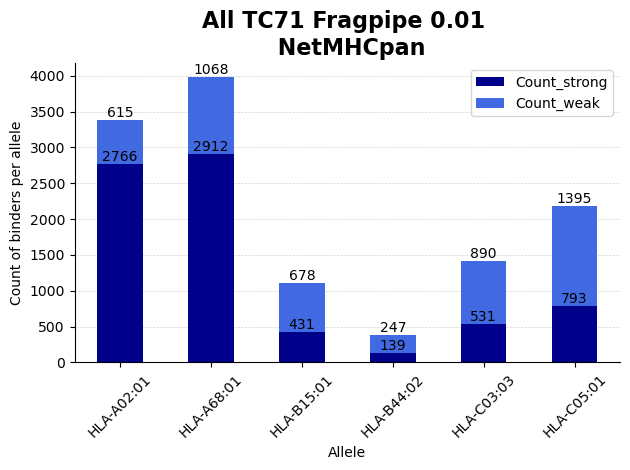

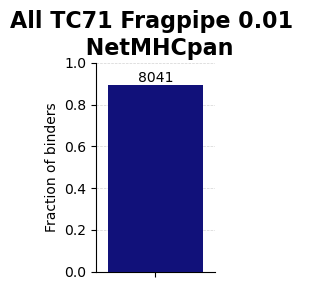

/tmp/ipykernel_4106705/740976126.py:53: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
/tmp/ipykernel_4106705/740976126.py:54: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


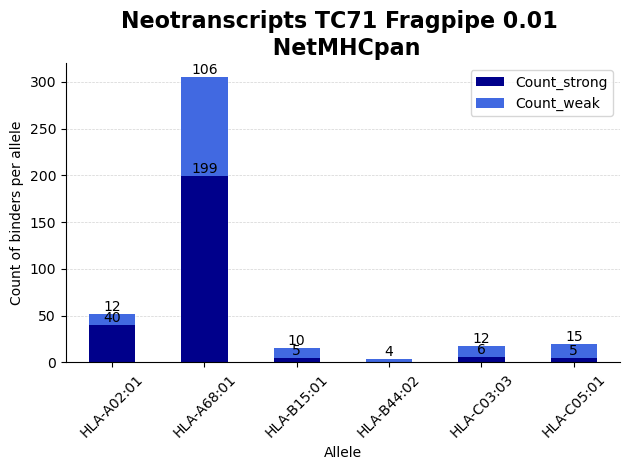

/tmp/ipykernel_4106705/740976126.py:75: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


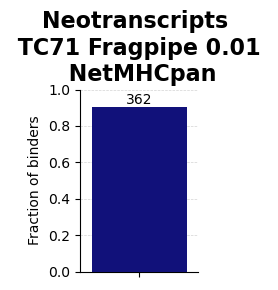

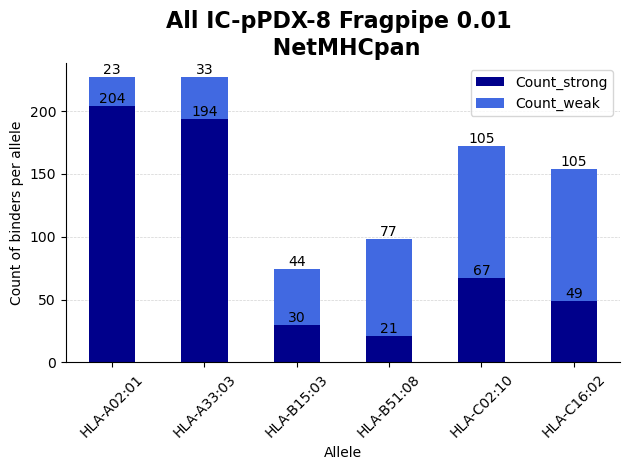

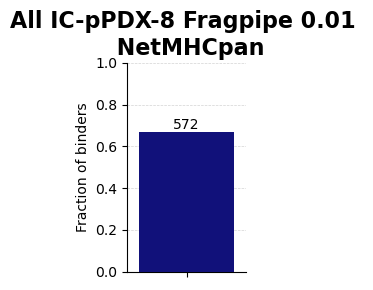

/tmp/ipykernel_4106705/740976126.py:53: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
/tmp/ipykernel_4106705/740976126.py:54: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


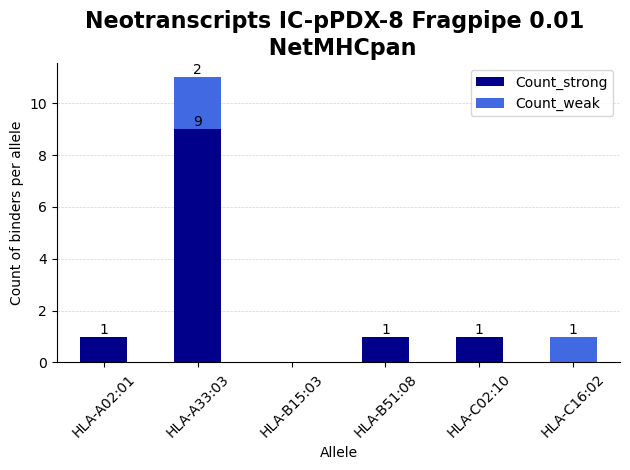

/tmp/ipykernel_4106705/740976126.py:75: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


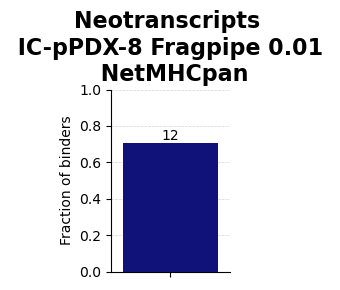

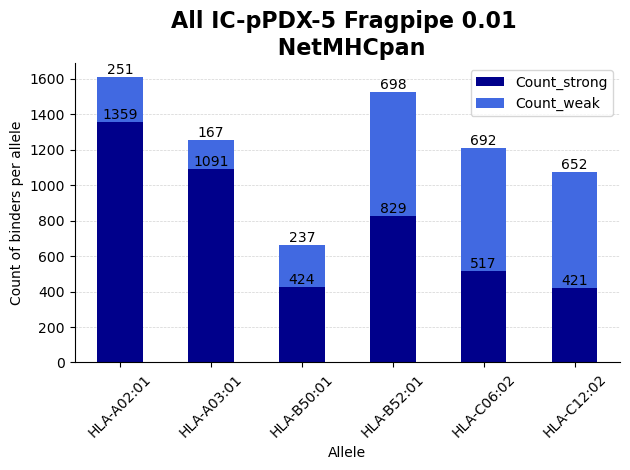

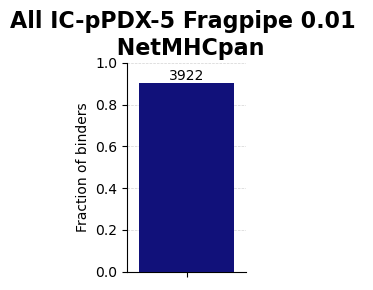

/tmp/ipykernel_4106705/740976126.py:53: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
/tmp/ipykernel_4106705/740976126.py:54: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


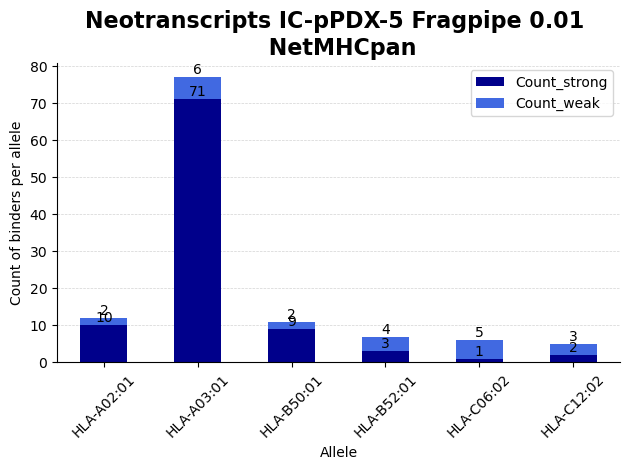

/tmp/ipykernel_4106705/740976126.py:75: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


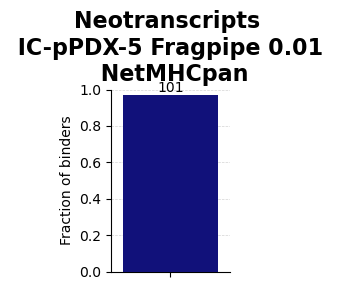

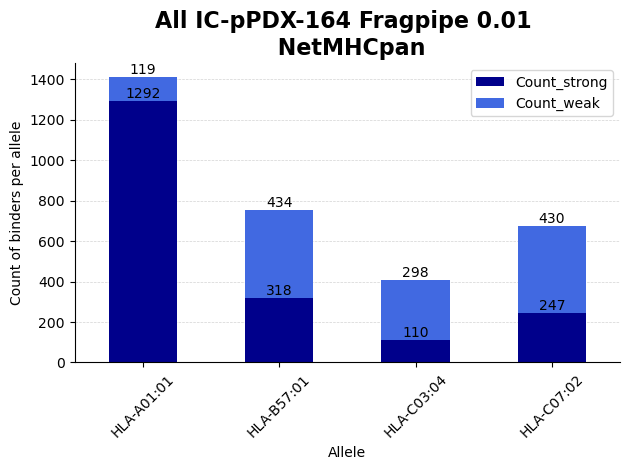

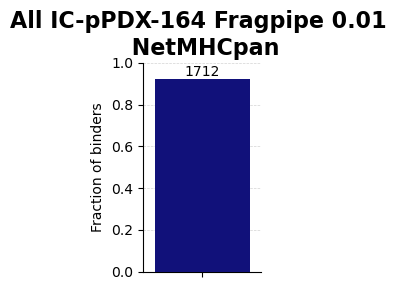

/tmp/ipykernel_4106705/740976126.py:53: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
/tmp/ipykernel_4106705/740976126.py:54: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


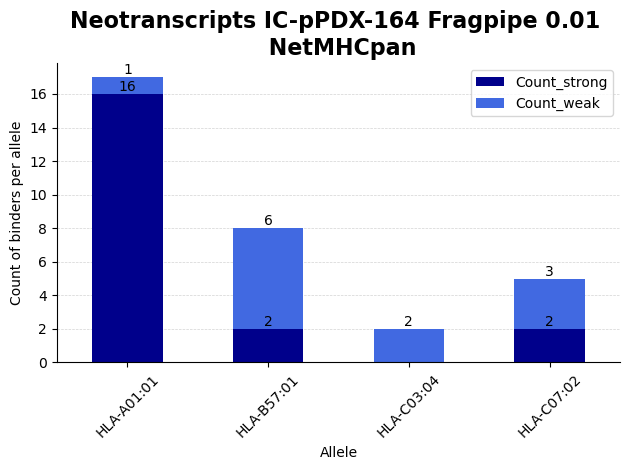

/tmp/ipykernel_4106705/740976126.py:75: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


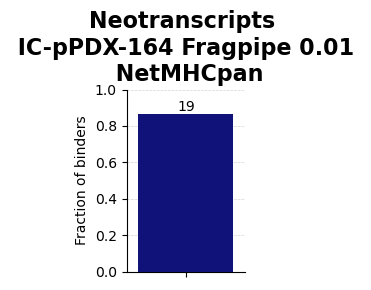

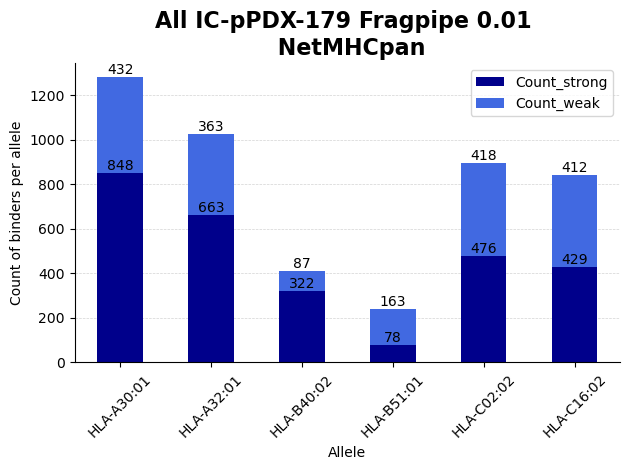

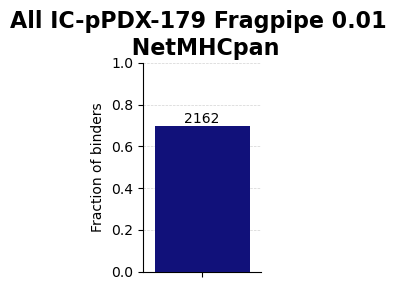

/tmp/ipykernel_4106705/740976126.py:53: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
/tmp/ipykernel_4106705/740976126.py:54: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


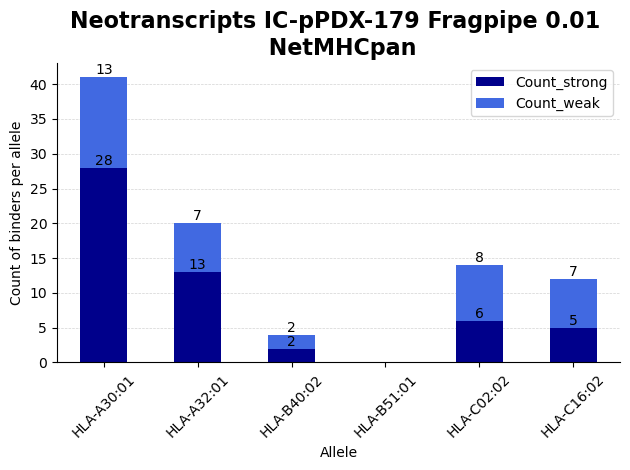

/tmp/ipykernel_4106705/740976126.py:75: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


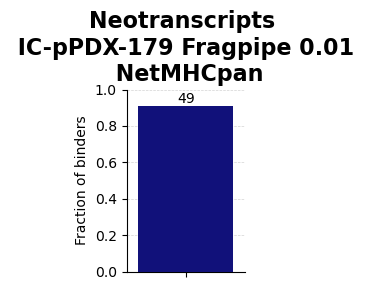

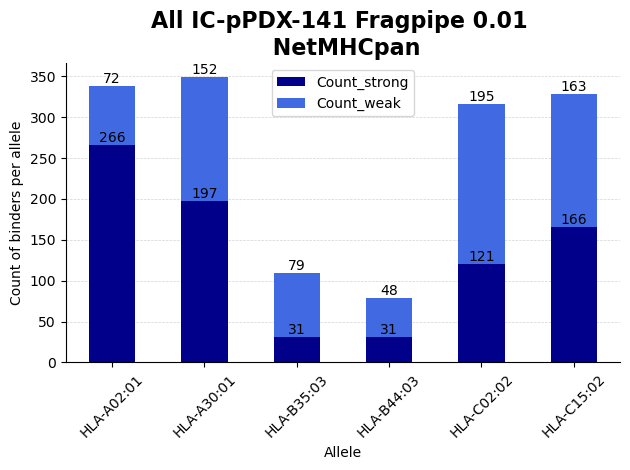

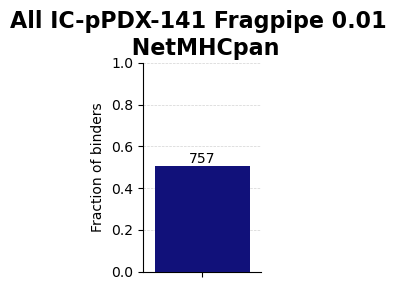

/tmp/ipykernel_4106705/740976126.py:53: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
/tmp/ipykernel_4106705/740976126.py:54: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


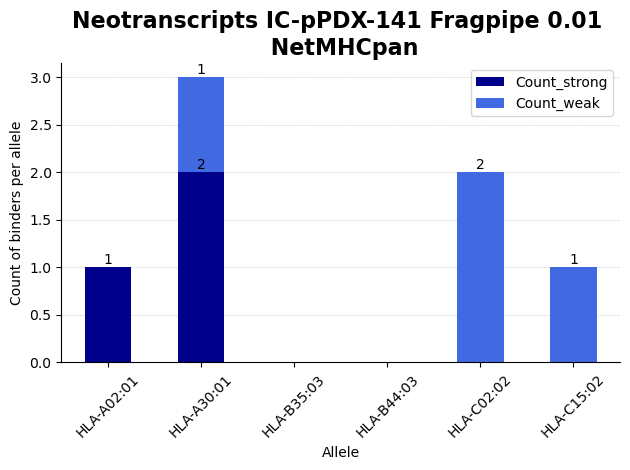

/tmp/ipykernel_4106705/740976126.py:75: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


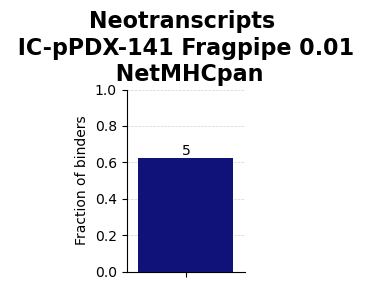

In [28]:
for run in runs:
    plot_NetMHCpan_binding_results(run, 'HLA_binding')

In [29]:
h = []
for run_ in runs:
    df = pd.read_csv(f'HLA_binding/{run_.sample}_{run_.search_engine}_{run_.fdr}_NetMHCpan_out.xls', sep="\t", header=1) 
    with open(f'HLA_binding/{run_.sample}_{run_.search_engine}_{run_.fdr}_NetMHCpan_out.xls') as my_file:
        hlas = my_file.readline().rstrip('\n').strip('\t').split('\t\t\t\t')
    ranks = [column for column in df.columns if column.startswith('EL_Rank')]
    new_cols = ['Peptide', 'NB']
    new_cols.extend(ranks)
    df = df[new_cols].rename(columns=dict(zip(ranks,list(map(lambda x: x+'_rank_NetMHCpan', hlas)))))
    df['SB'] = [[] for _ in range(len(df))]
    df['WB'] = [[] for _ in range(len(df))]
    for hla in hlas:
        df['SB'] = df.apply(
									lambda x: x['SB'] + [hla] if x[f'{hla}_rank_NetMHCpan'] < 0.5 else x['SB'],
									axis=1
							)
        df['WB'] = df.apply(
									lambda x: x['WB'] + [hla] if 0.5 <= x[f'{hla}_rank_NetMHCpan'] < 2 else x['WB'],
									axis=1
							)
    df['Binder'] = df['NB'] != 0
    columns_to_keep_df = ['Peptide', 'Binder', 'SB', 'WB']
    df = df[columns_to_keep_df]
    df = df.rename(columns={'Peptide': 'seq_clear'})
    
    res = run_.unique[run_.unique['class']=='Non canonical'][['seq_clear', 'accessions']].merge(df, on='seq_clear', how='left')
    res['Binder'] = res['Binder'].fillna(value=False)
    res['sample'] = run_.sample
    h.append(res[res['Binder']])
total_noncanonical_binder_peptides_fp = pd.concat(h, ignore_index=True)
total_noncanonical_binder_peptides_fp

/tmp/ipykernel_4106705/813397626.py:27: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
/tmp/ipykernel_4106705/813397626.py:27: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
/tmp/ipykernel_4106705/813397626.py:27: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


,seq_clear,accessions,Binder,SB,WB,sample
0,QVDTMSGVNY,ENST00000452185_4_123_NEOTRANSCRIPT,True,[HLA-A01:01],[],A673
1,ISDPGVQGY,ENSG00000070061__ENST00000675943__ncRNA__18__C...,True,"[HLA-A01:01, HLA-C07:02]",[],A673
2,YSETTLTSY,ENST00000656330_327_443_NEOTRANSCRIPT;ENST0000...,True,[HLA-A01:01],[HLA-C07:02],A673
3,ESDVSSALSY,ENST00000651170_461_1213_NEOTRANSCRIPT,True,[HLA-A01:01],[],A673
4,WQDAELGLY,ENSG00000103495_ENSG00000013364__ENST000005657...,True,[HLA-A01:01],[],A673
...,...,...,...,...,...,...
997,QVIGVVLQK,ENST00000297857_460_552_NEOTRANSCRIPT,True,[HLA-A30:01],[],IC-pPDX-141
998,KILDYMENL,TCONS_00808337_14985_15092_NEOTRANSCRIPT,True,[HLA-A02:01],"[HLA-C02:02, HLA-C15:02]",IC-pPDX-141
999,MGFPGHTTYK,TCONS_00182908_843_872_NEOTRANSCRIPT,True,[HLA-A30:01],[],IC-pPDX-141
1000,KSLAAELLVLK,ENSG00000163781__ENST00000260810__iORF__4__ATA...,True,[],[HLA-A30:01],IC-pPDX-141


In [ ]:
#Processing Casanovo output

In [30]:
samples = metadata['sample'].tolist()

In [ ]:
for sample in samples:
    print(f'python src/map_proteins.py --input_mztab Casanovo/Immunopeptidomics/data/results_{sample}.mztab --output_csv Casanovo/Immunopeptidomics/data/{sample}_annot.csv --canonical_proteome /mnt/raid0/HP/uniprotkb_with_isoforms_reviewed_true_AND_model_organ_2024_10_29.fasta --extra_fasta /mnt/raid0/ewing_sarcoma/data/databases/new_db_from_Luuk/20250916_EwS_ncORF.fasta')

python src/map_proteins.py --input_mztab Casanovo/Immunopeptidomics/data/results_A673.mztab --output_csv Casanovo/Immunopeptidomics/data/A673_annot.csv --canonical_proteome /mnt/raid0/HP/uniprotkb_with_isoforms_reviewed_true_AND_model_organ_2024_10_29.fasta --extra_fasta /mnt/raid0/ewing_sarcoma/data/databases/new_db_from_Luuk/20250916_EwS_ncORF.fasta
python src/map_proteins.py --input_mztab Casanovo/Immunopeptidomics/data/results_EW16.mztab --output_csv Casanovo/Immunopeptidomics/data/EW16_annot.csv --canonical_proteome /mnt/raid0/HP/uniprotkb_with_isoforms_reviewed_true_AND_model_organ_2024_10_29.fasta --extra_fasta /mnt/raid0/ewing_sarcoma/data/databases/new_db_from_Luuk/20250916_EwS_ncORF.fasta
python src/map_proteins.py --input_mztab Casanovo/Immunopeptidomics/data/results_EW7.mztab --output_csv Casanovo/Immunopeptidomics/data/EW7_annot.csv --canonical_proteome /mnt/raid0/HP/uniprotkb_with_isoforms_reviewed_true_AND_model_organ_2024_10_29.fasta --extra_fasta /mnt/raid0/ewing_sarco

In [31]:
#ncORF metadata annotation
meta = pd.read_csv('data/meta/20260219_EwS_ncORF_metadata_summary.tsv', sep='\t')

In [32]:
res = []
for sample in samples:
    df_casa = pd.read_csv(f'data/Immunopeptidomics/Casanovo/{sample}_annot.csv')
    df_casa = df_casa[(df_casa['extra_fasta_match_bool'])|(df_casa['extra_fasta_bool_with_IL_change'])]
    df_casa = df_casa[(~df_casa['canonical_proteome_match_bool'])&(~df_casa['canonical_proteome_bool_with_IL_change'])]
    df_casa['extra_fasta_match'] = df_casa['extra_fasta_match'].apply(ast.literal_eval)
    df_casa['extra_fasta_match_with_IL_change'] = df_casa['extra_fasta_match_with_IL_change'].apply(ast.literal_eval)
    df_casa['annot'] = df_casa['extra_fasta_match']  + df_casa['extra_fasta_match_with_IL_change']
    df_casa = df_casa.explode('annot')
    merge_casa_df = df_casa.merge(meta, left_on='annot', right_on='orf_id', how='left')
    merge_casa_df['sample'] = sample
    res.append(merge_casa_df)
final_casanovo_df = pd.concat(res)
final_casanovo_df

,PSH,sequence,PSM_ID,accession,unique,database,database_version,search_engine,search_engine_score[1],modifications,...,Peptides_WB,Number_WB,class,any_peptide_found_in_IP,result_A673,result_SKNMC,result_MHHES,result_TC106,result_RDES,sample
0,PSM,+43.006EAAAAEEAA,67,NaN,NaN,NaN,NaN,"[MS, MS:1003281, Casanovo, 4.2.1]",-0.680549,NaN,...,NaN,NaN,0.0,False,ns,ns,upregulated,ns,ns,A673
1,PSM,AEAAAAAAAAAAA,1100,NaN,NaN,NaN,NaN,"[MS, MS:1003281, Casanovo, 4.2.1]",-0.707111,NaN,...,NaN,NaN,0.0,False,not expressed,ns,ns,ns,ns,A673
2,PSM,VM+15.995PPPPASA,2015,NaN,NaN,NaN,NaN,"[MS, MS:1003281, Casanovo, 4.2.1]",0.975902,NaN,...,NaN,NaN,1.0,True,ns,ns,upregulated,ns,ns,A673
3,PSM,QVDTM+15.995SGVNY,3158,NaN,NaN,NaN,NaN,"[MS, MS:1003281, Casanovo, 4.2.1]",0.981440,NaN,...,NaN,NaN,0.0,False,ns,ns,ns,ns,upregulated,A673
4,PSM,LSDPGVQGY,4151,NaN,NaN,NaN,NaN,"[MS, MS:1003281, Casanovo, 4.2.1]",0.990398,NaN,...,NaN,NaN,3.0,True,not expressed,ns,ns,downregulated,ns,A673
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
504,PSM,LLPLLLPPL,31698,NaN,NaN,NaN,NaN,"[MS, MS:1003281, Casanovo, 4.2.1]",-0.080381,NaN,...,NaN,NaN,0.0,False,not expressed,ns,not expressed,not expressed,ns,IC-pPDX-141
505,PSM,LLPLLLPPL,31698,NaN,NaN,NaN,NaN,"[MS, MS:1003281, Casanovo, 4.2.1]",-0.080381,NaN,...,NaN,NaN,0.0,False,not expressed,ns,not expressed,not expressed,ns,IC-pPDX-141
506,PSM,+43.006LLGRVPV,35813,NaN,NaN,NaN,NaN,"[MS, MS:1003281, Casanovo, 4.2.1]",-0.318521,NaN,...,NaN,NaN,0.0,False,not expressed,ns,ns,ns,ns,IC-pPDX-141
507,PSM,+43.006LLGRVPV,35813,NaN,NaN,NaN,NaN,"[MS, MS:1003281, Casanovo, 4.2.1]",-0.318521,NaN,...,NaN,NaN,0.0,False,not expressed,ns,ns,ns,ns,IC-pPDX-141


In [ ]:
for sample in samples:
    with open(f"HLA_binding/{sample}_Casanovo.pep", 'w') as file:
        for pep in final_casanovo_df[final_casanovo_df['sample']==sample]['seq_clear'].unique().tolist():
            if 7<len(pep)<15:
                file.write(pep+'\n')

In [ ]:
for run_ in runs:
    print("/home/mariia/Desktop/netMHCpan-4.1/netMHCpan", 
                    f"-a {','.join(run_.hla)}",  # HLA alleles
                    f"-p {run_.sample}_Casanovo.pep",            # peptide list
                    f"-xls -xlsfile {run_.sample}_Casanovo_NetMHCpan_out.xls")

/home/mariia/Desktop/netMHCpan-4.1/netMHCpan -a HLA-A01:01,HLA-A02:01,HLA-B07:02,HLA-C07:02 -p A673_Casanovo.pep -xls -xlsfile A673_Casanovo_NetMHCpan_out.xls
/home/mariia/Desktop/netMHCpan-4.1/netMHCpan -a HLA-A02:01,HLA-B44:03,HLA-B51:01,HLA-C16:01,HLA-C05:01 -p EW16_Casanovo.pep -xls -xlsfile EW16_Casanovo_NetMHCpan_out.xls
/home/mariia/Desktop/netMHCpan-4.1/netMHCpan -a HLA-A02:01,HLA-A03:01,HLA-B35:01,HLA-B51:01,HLA-C04:01,HLA-C15:02 -p EW7_Casanovo.pep -xls -xlsfile EW7_Casanovo_NetMHCpan_out.xls
/home/mariia/Desktop/netMHCpan-4.1/netMHCpan -a HLA-A02:01,HLA-A30:04,HLA-B51:08,HLA-B44:02,HLA-C05:01,HLA-C16:02 -p STA-ET-1_Casanovo.pep -xls -xlsfile STA-ET-1_Casanovo_NetMHCpan_out.xls
/home/mariia/Desktop/netMHCpan-4.1/netMHCpan -a HLA-A68:01,HLA-A02:01,HLA-B44:02,HLA-B15:01,HLA-C03:03,HLA-C05:01 -p TC71_Casanovo.pep -xls -xlsfile TC71_Casanovo_NetMHCpan_out.xls
/home/mariia/Desktop/netMHCpan-4.1/netMHCpan -a HLA-A02:01,HLA-A33:03,HLA-B15:03,HLA-B51:08,HLA-C16:02,HLA-C02:10 -p IC-pP

In [33]:
h = []
for run_ in runs:
    df = pd.read_csv(f'HLA_binding/{run_.sample}_Casanovo_NetMHCpan_out.xls', sep="\t", header=1) 
    with open(f'HLA_binding/{run_.sample}_Casanovo_NetMHCpan_out.xls') as my_file:
        hlas = my_file.readline().rstrip('\n').strip('\t').split('\t\t\t\t')
    ranks = [column for column in df.columns if column.startswith('EL_Rank')]
    new_cols = ['Peptide', 'NB']
    new_cols.extend(ranks)
    df = df[new_cols].rename(columns=dict(zip(ranks,list(map(lambda x: x+'_rank_NetMHCpan', hlas)))))
    df['SB'] = [[] for _ in range(len(df))]
    df['WB'] = [[] for _ in range(len(df))]
    for hla in hlas:
        df['SB'] = df.apply(
									lambda x: x['SB'] + [hla] if x[f'{hla}_rank_NetMHCpan'] < 0.5 else x['SB'],
									axis=1
							)
        df['WB'] = df.apply(
									lambda x: x['WB'] + [hla] if 0.5 <= x[f'{hla}_rank_NetMHCpan'] < 2 else x['WB'],
									axis=1
							)
    df['Binder'] = df['NB'] != 0
    columns_to_keep_df = ['Peptide', 'Binder', 'SB', 'WB']
    df = df[columns_to_keep_df]
    df = df.rename(columns={'Peptide': 'seq_clear'})
    
    res = final_casanovo_df[['seq_clear', 'annot']].merge(df, on='seq_clear', how='left')
    res['Binder'] = res['Binder'].fillna(value=False)
    res['sample'] = run_.sample
    h.append(res[res['Binder']])
total_noncanonical_binder_peptides_casanovo = pd.concat(h, ignore_index=True)
total_noncanonical_binder_peptides_casanovo

/tmp/ipykernel_4106705/4241533029.py:27: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
/tmp/ipykernel_4106705/4241533029.py:27: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
/tmp/ipykernel_4106705/4241533029.py:27: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
/tmp/ipykernel_4106705/4241533029.py:27: FutureWarning: Downcasting object dtype arra

,seq_clear,annot,Binder,SB,WB,sample
0,VMPPPPASA,ENST00000525774_40_243,True,[HLA-A02:01],[HLA-C07:02],A673
1,QVDTMSGVNY,ENST00000452185_4_123,True,[HLA-A01:01],[],A673
2,LSDPGVQGY,ENST00000675765_266_397,True,[HLA-A01:01],[HLA-C07:02],A673
3,LSDPGVQGY,ENSG00000070061__ENST00000675943__ncRNA__18__CTG,True,[HLA-A01:01],[HLA-C07:02],A673
4,LSDPGVQGY,ENST00000675765_266_397,True,[HLA-A01:01],[HLA-C07:02],A673
...,...,...,...,...,...,...
8007,LLPLLLPPL,ENSG00000175161_ENSG00000243915__ENST000004851...,True,[],[HLA-A02:01],IC-pPDX-141
8008,LLPLLLPPL,ENSG00000175161_ENSG00000243915__ENST000004851...,True,[],[HLA-A02:01],IC-pPDX-141
8009,LLPLLLPPL,ENSG00000175161_ENSG00000243915__ENST000004851...,True,[],[HLA-A02:01],IC-pPDX-141
8010,LLPLLLPPL,ENSG00000175161_ENSG00000243915__ENST000004851...,True,[],[HLA-A02:01],IC-pPDX-141


In [34]:
total_noncanonical_binder_peptides_fp['accessions'] = total_noncanonical_binder_peptides_fp['accessions'].apply(lambda x: x.split(';'))
total_noncanonical_binder_peptides_fp

,seq_clear,accessions,Binder,SB,WB,sample
0,QVDTMSGVNY,[ENST00000452185_4_123_NEOTRANSCRIPT],True,[HLA-A01:01],[],A673
1,ISDPGVQGY,[ENSG00000070061__ENST00000675943__ncRNA__18__...,True,"[HLA-A01:01, HLA-C07:02]",[],A673
2,YSETTLTSY,"[ENST00000656330_327_443_NEOTRANSCRIPT, ENST00...",True,[HLA-A01:01],[HLA-C07:02],A673
3,ESDVSSALSY,[ENST00000651170_461_1213_NEOTRANSCRIPT],True,[HLA-A01:01],[],A673
4,WQDAELGLY,[ENSG00000103495_ENSG00000013364__ENST00000565...,True,[HLA-A01:01],[],A673
...,...,...,...,...,...,...
997,QVIGVVLQK,[ENST00000297857_460_552_NEOTRANSCRIPT],True,[HLA-A30:01],[],IC-pPDX-141
998,KILDYMENL,[TCONS_00808337_14985_15092_NEOTRANSCRIPT],True,[HLA-A02:01],"[HLA-C02:02, HLA-C15:02]",IC-pPDX-141
999,MGFPGHTTYK,[TCONS_00182908_843_872_NEOTRANSCRIPT],True,[HLA-A30:01],[],IC-pPDX-141
1000,KSLAAELLVLK,[ENSG00000163781__ENST00000260810__iORF__4__AT...,True,[],[HLA-A30:01],IC-pPDX-141


In [35]:
total_noncanonical_binder_peptides_fp = total_noncanonical_binder_peptides_fp.explode('accessions')

In [36]:
ncORFs_detected_fp = set([x.replace('_NEOTRANSCRIPT', '') for x in total_noncanonical_binder_peptides_fp['accessions'].unique().tolist()])
ncORFs_detected_casanovo = set(total_noncanonical_binder_peptides_casanovo['annot'].unique().tolist())

In [37]:
meta['detected_ip_fp'] = meta['orf_id'].apply(lambda x: x in ncORFs_detected_fp)
meta['detected_ip_casanovo'] = meta['orf_id'].apply(lambda x: x in ncORFs_detected_casanovo)

In [12]:
palette = {
    "Neogene ORF": "#1b365d",
    "In-frame ORF": "#6ea9d2",
    "ORF_variant": "#FFB347",
    "Canonical_protein": "#77DD77",
    "lncRNA ORF": "#D32F2F",
    "dORF": "#32936F",
    "doORF": "#80baa5",
    "intORF": "#d9d9d9",
    "uORF": "#6c57b7",
    "uoORF": "#a091d4",
    "pseudogene ORF": "#F15BB5",
    "Out-of-frame ORF": "#D0E8F8",
    "unannotated gene ORF": "#e0c219"
}

In [43]:
meta.to_csv("meta_with_detection.csv", index=False)

In [3]:
meta = pd.read_csv("meta_with_detection.csv")
meta

,orf_id,ORF_ranges,Protein,gene_id,gene_biotype,gene_name,transcript_id,uniprot_gn_ids,cl_mean,ps_mean,...,result_A673,result_SKNMC,result_MHHES,result_TC106,result_RDES,detected_ip_fp,detected_ip_casanovo,detected_MSK,detected_tr,detected_DKFZ
0,ENSG00000159167__ENST00000290271__uORF__2__GTG,8:23854633-23854746,MAAAAAAAAAAAAAEAPVAAAASPATTTKKNPHQILT,ENSG00000159167,protein_coding,STC1,ENST00000290271,A0A0H3W641;P52823,1.187192,2.508946,...,not expressed,not expressed,upregulated,ns,ns,False,False,False,False,False
1,ENST00000291041_23_121,16:67893276-67908682,MAAAAAAAAAAAIARRWPAEPPRRRRARRPREV,ENSG00000159792,protein_coding,PSKH1,ENST00000291041,P11801;A0A087WZT9,23.079040,17.597305,...,ns,ns,ns,ns,ns,True,True,False,False,False
2,ENST00000216727_182_1099,14:23321470-23325283,MAAAAAAAAAAGAAGGRGSGPGRRRHLVPGAGGEAGEGAPGGAGDY...,ENSG00000100836,protein_coding,PABPN1,ENST00000216727,B4DEH8;Q86U42;G3V4T2,72.570950,51.634440,...,NaN,NaN,NaN,NaN,NaN,False,False,False,False,False
3,ENST00000397276_14_901,14:23321470-23324296,MAAAAAAAAAAGAAGGRGSGPGRRRHLVPGAGGEAGEGAPGGAGDY...,ENSG00000100836,protein_coding,PABPN1,ENST00000397276,B4DEH8;Q86U42;G3V4T2,71.136807,50.211111,...,ns,ns,ns,ns,ns,False,False,False,False,False
4,ENST00000354300_17_85,12:110583234-110583302,MAAAAAAAAAGTSVGLRRRSRRF,ENSG00000196850,protein_coding,PPTC7,ENST00000354300,Q8NI37,14.741234,14.913901,...,not expressed,ns,upregulated,ns,ns,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
62178,ENSG00000116604__TCONS_00065632__ncRNA__9__ATT,1:156483398-156500599,MYYSPRPELRLPGVEDPPDQGRGLPALCRDNTVPPAGLEAVQKVSCRP,ENSG00000116604,protein_coding,MEF2D,TCONS_00065632,Q14814;Q05BX2,12.438524,33.178861,...,ns,ns,ns,ns,ns,False,False,False,False,False
62179,ENST00000552151_8_454,12:70310970-70330470,MYYSQSSMFPHRSEKDMLASPSTSGQLSQFGASLYGQQSALGLPMR...,ENSG00000111596,protein_coding,CNOT2,ENST00000552151,F8VSK9;Q9NZN8;F8VUB4;F8W145;F8VPX5;F8VVY1;F8VV...,12.182117,23.360930,...,ns,ns,ns,ns,ns,False,False,False,False,False
62180,ENST00000495930_268_459,13:112875798-112875989,MYYVFIQMLSSGPAWLAIVLLVTISLLPDVLKKVLCRQLWPTATER...,ENSG00000068650,protein_coding,ATP11A,ENST00000495930,P98196;E9PEJ6;A2A3G9;A0A087WVE8,6.739418,19.103163,...,not expressed,ns,ns,ns,ns,False,False,False,False,False
62181,ENSG00000181392_ENSG00000239382__ENST000004904...,19:36010923-36013077,MYYVPDFISKEEEEYLLRQVFNAPKPKWTQLSGRKLQNWGPHCLPQ...,ENSG00000239382,protein_coding,ALKBH6,ENST00000490483,Q3KRA9;E9PI76;S4R3C7;H0YD83,10.796175,7.697037,...,ns,ns,ns,ns,ns,False,False,False,False,False


In [4]:
meta['orf_cathegoty_toplot'] = meta['neotranscript_orf_type'].where(meta['neotranscript_orf_type'] != 'Non-canonical ORF general', meta['orf_category_new'])

In [5]:
meta['orf_cathegoty_toplot'].value_counts()

orf_cathegoty_toplot
ORF_variant             24376
ORF_annotated           12755
uORF                    11137
intORF                   4159
uoORF                    3777
lncRNA ORF               3402
pseudogene ORF            725
dORF                      650
Neogene ORF               364
unannotated gene ORF      342
doORF                     242
In-frame ORF              210
Out-of-frame ORF           44
Name: count, dtype: int64

In [6]:
def assign_label(x):
		if x['detected_ip_fp'] and not(x['detected_ip_casanovo']):
				return 'by Fragpipe'
		elif not(x['detected_ip_fp']) and x['detected_ip_casanovo']:
				return 'by Casanovo'
		elif x['detected_ip_fp'] and x['detected_ip_casanovo']:
				return 'by Fragpipe and Casanovo'
		else:
				return 'not detected'

In [15]:
desired_order = [
    'by Fragpipe',
    'by Casanovo',
    'by Fragpipe and Casanovo'
]

In [8]:
from pandas.api.types import CategoricalDtype

In [9]:
MY_ORDER = ['Neogene ORF', 'In-frame ORF', 'Out-of-frame ORF', 'lncRNA ORF', 'dORF', 'doORF', 'intORF', 'uORF', 'uoORF', 'pseudogene ORF', 'unannotated gene ORF']
MY_CAT_ORDER = CategoricalDtype(MY_ORDER, ordered=True)

meta['orf_cathegoty_toplot'] = meta['orf_cathegoty_toplot'].astype(MY_CAT_ORDER)
meta = meta.sort_values('orf_cathegoty_toplot')

In [20]:
hatch_map = {
    'by Fragpipe': '',
    'by Casanovo': '...',      # dots
    'by Fragpipe and Casanovo': 'xxx',
}

In [24]:
from matplotlib.patches import Patch
import matplotlib.patches as mpatches

legend_handles = [
    Patch(facecolor="white", edgecolor="black", hatch="",    label="by Fragpipe"),
    Patch(facecolor="white", edgecolor="black", hatch="...", label="by Casanovo"),
    Patch(facecolor="white", edgecolor="black", hatch="xxx", label="by Fragpipe and Casanovo"),
]

patches = [
    mpatches.Patch(color=color, label=label)
    for label, color in palette.items()
]

In [25]:
plt.rcParams['text.color'] = 'black'
plt.rcParams['axes.labelcolor'] = 'black'
plt.rcParams['xtick.color'] = 'black'
plt.rcParams['ytick.color'] = 'black'

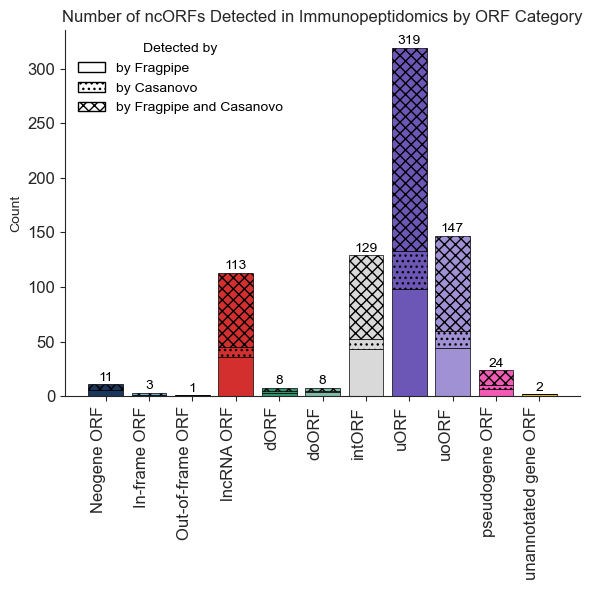

In [27]:
import matplotlib
matplotlib.rcParams['pdf.fonttype'] = 42        # ← renders text as text in Illustrator (Type 1 → TrueType)
matplotlib.rcParams['ps.fonttype'] = 42
matplotlib.rcParams['font.family'] = 'Arial'    # ← Arial font

df = meta[meta['orf_cathegoty_toplot']!='ORF_variant'][['orf_id', 'orf_cathegoty_toplot', 'detected_ip_fp', 'detected_ip_casanovo']]
df["Detected"] = df.apply(
    lambda x: assign_label(x), 
        axis=1
)
df = df[df['Detected']!='not detected']
counts = df.groupby(["orf_cathegoty_toplot", "Detected"]).size().unstack(fill_value=0)
sns.set_style("ticks")
plt.figure(figsize=(6, 6))
x = counts.index
bottom = None
totals = counts.sum(axis=1)  # ← for count labels on top

for label in desired_order:
    bars = plt.bar(
        x,
        counts[label],
        bottom=bottom,
        color=[palette[c] for c in x],
        hatch=hatch_map[label],
        edgecolor="black",
        linewidth=0.5,
        label=label
    )
    bottom = counts[label] if bottom is None else bottom + counts[label]

# ← add count labels on top of each bar
for i, (orf_cat, total) in enumerate(totals.items()):
    plt.text(
        i, total + 0.5,
        str(total),
        ha='center', va='bottom',
        fontsize=10, color='black'
    )

leg = plt.legend(
    handles=legend_handles,
    title="Detected by",
    frameon=False
)
plt.setp(leg.get_texts(), color="black")
plt.setp(leg.get_title(), color="black")
plt.tick_params(axis='x', labelsize=12)
plt.tick_params(axis='y', labelsize=12)
plt.title("Number of ncORFs Detected in Immunopeptidomics by ORF Category")
plt.ylabel("Count")
plt.xticks(rotation=90, ha='right')
sns.despine()
plt.tight_layout()
plt.savefig("ncORF_detection_by_category.pdf", format="pdf")
plt.show()

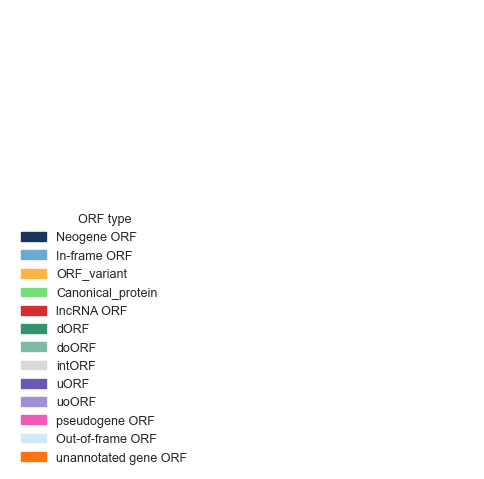

In [31]:
# Save legends and colorbar as a separate figure
fig_leg, (ax_leg, ax_cbar) = plt.subplots(1, 2, figsize=(6, 5), gridspec_kw={'width_ratios': [1, 0.3]})
ax_leg.axis('off')
ax_cbar.axis('off')

# Legend for ORF type
leg = ax_leg.legend(
    handles=patches,
    title="ORF type",
    loc="upper left",
    bbox_to_anchor=(0, 0.5),
    frameon=False,
    fontsize=9,
    title_fontsize=9
)


plt.savefig('IP_legend_colorbars_06032026.pdf', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
meta[meta['detected_ip_fp']|meta['detected_ip_casanovo']]['neotranscript_orf_type'].value_counts()

neotranscript_orf_type
Non-canonical ORF general    750
ORF_variant                  170
Neogene ORF                   11
In-frame truncated             2
In-frame non-canonical         1
Out-of-frame novel             1
Name: count, dtype: int64

In [ ]:
labels = [ "Non-canonical ORF general", "ORF_variant", "Neogene ORF", "In-frame truncated", "In-frame non-canonical", "Out-of-frame novel" ] 
counts = np.array([750, 170, 11, 2, 1, 1]) 
colors = [palette[l] for l in labels] 

fig, ax = plt.subplots(figsize=(6, 6)) 
wedges, _ = ax.pie( counts, colors=colors, startangle=90, counterclock=False, labels=None, wedgeprops=dict(edgecolor="white", linewidth=1), ) 

total = counts.sum() 
for wedge, label, count in zip(wedges, labels, counts): 
		angle = (wedge.theta2 + wedge.theta1) / 2 
		x, y = np.cos(np.deg2rad(angle)), np.sin(np.deg2rad(angle)) 
		if count >= 20: ax.text( 0.7 * x, 0.7 * y, f"{label}\n{count}", ha="center", va="center", fontsize=9, ) else: if label == "Neogene ORF": ax.annotate( f"{label} ({count})", xy=(x, y), xytext=(1.25 * np.sign(x), 1.25 * y), arrowprops=dict( arrowstyle="-", linewidth=0.8, color="black", ), ha="left" if x > 0 else "right", va="center", fontsize=8, ) elif label == "In-frame truncated": ax.annotate( f"{label} ({count})", xy=(x, y), xytext=(1.25 * np.sign(x), 1.25 * (y-0.05)), arrowprops=dict( arrowstyle="-", linewidth=0.8, color="black", ), ha="left" if x > 0 else "right", va="center", fontsize=8, ) elif label == "Out-of-frame novel": ax.annotate( f"{label} ({count})", xy=(x, y), xytext=(1.25 * np.sign(x), 1.25 * (y-0.1)), arrowprops=dict( arrowstyle="-", linewidth=0.8, color="black", ), ha="left" if x > 0 else "right", va="center", fontsize=8, ) ax.set_title("Number of ncORFs Detected in Immunopeptidomics by ORF Category", fontsize=12) ax.set_aspect("equal") plt.tight_layout() plt.show()

SyntaxError: invalid syntax (3210178284.py, line 1)